In [7]:

from google.colab import userdata
from google import genai

# Use the exact secret name shown in your Colab
api_key = userdata.get("Gemini_API_Key")

client = genai.Client(api_key=api_key)

print("API key retrieved. Testing connection...")

response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents="Reply with exactly: Connection successful"
)

print(response.text)


API key retrieved. Testing connection...
Connection successful


In [9]:

!pip -q install pypdf tiktoken

from pathlib import Path
from pypdf import PdfReader

# Find the IMF Canada PDF uploaded into Colab
pdf_files = list(Path("/content").glob("imf_canada_2024*.pdf"))

if not pdf_files:
    raise FileNotFoundError(
        "IMF PDF not found. Please upload the PDF again."
    )

pdf_path = pdf_files[0]

# Read the PDF
reader = PdfReader(str(pdf_path))

print("PDF loaded successfully!")
print("File name:", pdf_path.name)
print("Total pages:", len(reader.pages))

# Preview text from the first page
print("\nFirst page text:")
print((reader.pages[0].extract_text() or "")[:1000])



PDF loaded successfully!
File name: imf_canada_2024_article_iv_country_report_24_128.pdf
Total pages: 129

First page text:
 
© 2024 International Monetary Fund 
IMF Country Report No. 24/128 
CANADA 
2024 ARTICLE IV CONSULTATION—PRESS RELEASE 
AND STAFF REPORT 
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions 
with members, usually every year. In the context of the 2024 Article IV consultation with 
Canada, the following documents have been released and are included in this package: 
 
• A Press Release summarizing the views of the Executive Board as expressed during its 
July 10, 2024, consideration of the staff report that concluded the Article IV 
consultation with Canada. 
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s 
consideration on July 10, 2024, following discussions that ended on June 5, 2024, with 
the officials of Canada on economic developments and policies. Based on information 
available at the t

In [10]:

import re

def clean_text(text):
    # Remove unnecessary whitespace
    text = text.replace("\xa0", " ")
    text = re.sub(r"[ \t]+", " ", text)

    # Remove repeated blank lines
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()

# Extract and clean all PDF pages
pages = []

for i, page in enumerate(reader.pages):
    raw_text = page.extract_text() or ""
    pages.append({
        "page": i + 1,
        "text": clean_text(raw_text)
    })

full_text = "\n\n".join(
    page["text"] for page in pages
)

print("Total pages processed:", len(pages))
print("Total words:", len(full_text.split()))
print("Total characters:", len(full_text))
print("\nText extraction successful!")


Total pages processed: 129
Total words: 42629
Total characters: 292558

Text extraction successful!


In [11]:

import re

def advanced_clean_text(text):
    cleaned_lines = []

    for line in text.splitlines():
        line = line.replace("\xa0", " ")
        line = re.sub(r"[ \t]+", " ", line).strip()

        if not line:
            continue

        # Remove repetitive page headers
        if line.upper() == "CANADA":
            continue

        # Remove IMF page footers
        if re.fullmatch(
            r"(\d+\s+)?INTERNATIONAL MONETARY FUND(\s+\d+)?",
            line,
            flags=re.IGNORECASE
        ):
            continue

        # Remove standalone page numbers
        if re.fullmatch(r"\d{1,3}", line):
            continue

        cleaned_lines.append(line)

    return "\n".join(cleaned_lines)


cleaned_pages = []

for page in pages:
    cleaned_pages.append({
        "page": page["page"],
        "text": advanced_clean_text(page["text"])
    })

cleaned_full_text = "\n\n".join(
    p["text"] for p in cleaned_pages
)

with open("/content/imf_cleaned_text.txt", "w", encoding="utf-8") as f:
    f.write(cleaned_full_text)

print("Advanced cleaning completed!")
print("Original characters:", len(full_text))
print("Cleaned characters:", len(cleaned_full_text))
print("Cleaned text saved successfully.")

import tiktoken
import json

tokenizer = tiktoken.get_encoding("cl100k_base")

CHUNK_SIZE = 450
OVERLAP = 50
STEP_SIZE = CHUNK_SIZE - OVERLAP

chunks = []

for page in cleaned_pages:

    tokens = tokenizer.encode(page["text"])

    for start in range(0, len(tokens), STEP_SIZE):
        selected_tokens = tokens[start:start + CHUNK_SIZE]

        # Avoid very small trailing chunks
        if len(selected_tokens) < 100 and start > 0:
            break

        if not selected_tokens:
            continue

        chunk_text = tokenizer.decode(selected_tokens)

        chunks.append({
            "chunk_id": len(chunks),
            "pdf_page": page["page"],
            "token_count": len(selected_tokens),
            "text": chunk_text
        })

        if start + CHUNK_SIZE >= len(tokens):
            break

# Save chunks to JSON
with open("/content/imf_chunks.json", "w", encoding="utf-8") as f:
    json.dump(chunks, f, indent=2, ensure_ascii=False)

print("Token-aware chunking completed!")
print("Total chunks:", len(chunks))
print("Chunk size:", CHUNK_SIZE)
print("Overlap:", OVERLAP)
print("JSON file saved successfully.")

print("Total number of chunks:", len(chunks))

print("\nFirst chunk details:")
print("Chunk ID:", chunks[0]["chunk_id"])
print("PDF Page:", chunks[0]["pdf_page"])
print("Token Count:", chunks[0]["token_count"])

print("\nFirst 500 characters:")
print(chunks[0]["text"][:500])

print("\nAverage token count:",
      round(sum(c["token_count"] for c in chunks) / len(chunks), 2))


Advanced cleaning completed!
Original characters: 292558
Cleaned characters: 281456
Cleaned text saved successfully.
Token-aware chunking completed!
Total chunks: 205
Chunk size: 450
Overlap: 50
JSON file saved successfully.
Total number of chunks: 205

First chunk details:
Chunk ID: 0
PDF Page: 1
Token Count: 344

First 500 characters:
© 2024 International Monetary Fund
IMF Country Report No. 24/128
2024 ARTICLE IV CONSULTATION—PRESS RELEASE
AND STAFF REPORT
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions
with members, usually every year. In the context of the 2024 Article IV consultation with
Canada, the following documents have been released and are included in this package:
• A Press Release summarizing the views of the Executive Board as expressed during its
July 10, 2024, considera

Average token count: 325.59


In [14]:

import re

section_headings = {
    "CONTEXT": "Context",
    "RECENT DEVELOPMENTS": "Recent Developments",
    "OUTLOOK AND RISKS": "Outlook and Risks",
    "A. NORMALIZING AND STRENGTHENING MACROECONOMIC POLICIES": "Macroeconomic Policies",
    "B. SAFEGUARDING FINANCIAL STABILITY": "Financial Stability",
    "C. CONFRONTING STRUCTURAL CHALLENGES": "Structural Challenges",
    "STAFF APPRAISAL": "Staff Appraisal"
}

report_sections = {}
current_section = None

# Main staff report narrative is on PDF pages 8-26
for page in cleaned_pages:
    if not 8 <= page["page"] <= 26:
        continue

    for line in page["text"].splitlines():
        normalized = re.sub(
            r"\s+", " ", line.strip()
        ).upper()

        if normalized in section_headings:
            current_section = section_headings[normalized]
            report_sections[current_section] = []
            continue

        if current_section:
            report_sections[current_section].append(line)

report_sections = {
    name: "\n".join(lines)
    for name, lines in report_sections.items()
}

print("Sections identified:", len(report_sections))

for name, text in report_sections.items():
    print(f"{name}: {len(text.split())} words")


Sections identified: 7
Context: 380 words
Recent Developments: 1604 words
Outlook and Risks: 983 words
Macroeconomic Policies: 1933 words
Financial Stability: 1144 words
Structural Challenges: 1794 words
Staff Appraisal: 725 words


In [15]:

from google.genai import types

# Use the model from your successful Gemini API test
MODEL = "gemini-3.5-flash-lite"

section_name = "Recent Developments"
section_text = report_sections[section_name]

prompt = f"""
You are a professional IMF macroeconomic analyst.

Summarise the following section from the
2024 IMF Canada Article IV Staff Report.

SECTION: {section_name}

Requirements:
1. Use fewer than 100 words.
2. Explain the most important economic developments.
3. Include important numerical indicators.
4. Mention major financial risks where relevant.
5. Use only information from the supplied report.
6. Do not invent facts or figures.
7. Write in clear academic English.

SOURCE TEXT:
{section_text}
"""

response = client.models.generate_content(
    model=MODEL,
    contents=prompt,
    config=types.GenerateContentConfig(
        temperature=0,
        max_output_tokens=700
    )
)

summary = response.text

if not summary:
    raise ValueError("Gemini returned an empty summary.")

print("SECTION:", section_name)
print("\nGEMINI SUMMARY:\n")
print(summary)

print("\nWord count:", len(summary.split()))


SECTION: Recent Developments

GEMINI SUMMARY:

In 2023, Canada's real GDP growth slowed to 1.2 percent, and headline inflation fell to 2.9 percent by May 2024. Surging immigration spiked population growth to 3.2 percent, driving a severe housing crisis with vacancy rates near 1 percent. The unemployment rate rose to 6.2 percent, while the current account deficit widened due to lower commodity prices. The banking sector remains resilient with low non-performing loans, though high household indebtedness, rising auto loan arrears, and nonbank financial institutions' reliance on leverage and repo financing present notable financial vulnerabilities.

Word count: 88


In [16]:

import json
import time
from pathlib import Path
from google.genai import types

output_file = Path("/content/imf_section_summaries.json")

# Load saved summaries if this cell has run before
if output_file.exists():
    with open(output_file, "r", encoding="utf-8") as f:
        section_summaries = json.load(f)
else:
    section_summaries = {}

# Reuse the successful Recent Developments summary
if (
    "summary" in globals()
    and isinstance(summary, str)
    and len(summary.split()) < 100
):
    section_summaries.setdefault(
        "Recent Developments", summary
    )

for section_name, section_text in report_sections.items():

    # Do not repeat completed API requests
    if section_name in section_summaries:
        print("Already completed:", section_name)
        continue

    prompt = f"""
You are an IMF financial and macroeconomic analyst.

Summarise the following section from the
2024 IMF Canada Article IV Staff Report.

SECTION: {section_name}

Requirements:
1. Summarise in 70-90 words.
2. Identify the most important economic findings.
3. Include relevant numerical indicators.
4. Mention important financial risks.
5. Include key policy recommendations where relevant.
6. Use only the supplied source text.
7. Do not invent facts or numerical values.
8. Return only the summary, without a heading.

SOURCE:
{section_text}
"""

    try:
        response = client.models.generate_content(
            model=MODEL,
            contents=prompt,
            config=types.GenerateContentConfig(
                temperature=0,
                max_output_tokens=700
            )
        )

        result = response.text

        if not result:
            raise ValueError("Empty Gemini response")

        section_summaries[section_name] = result.strip()

        # Save after EVERY successful request
        with open(output_file, "w", encoding="utf-8") as f:
            json.dump(
                section_summaries,
                f,
                indent=2,
                ensure_ascii=False
            )

        print(
            "Completed:", section_name,
            "| Words:", len(result.split())
        )

        # Short pause to reduce rapid API requests
        time.sleep(3)

    except Exception as error:
        print("Stopped at:", section_name)
        print("Error:", error)
        print("Completed summaries have been saved.")
        break


print("\nTOTAL SUMMARIES:", len(section_summaries))

print("\nWORD COUNT VALIDATION:")
for name, result in section_summaries.items():
    count = len(result.split())
    status = "PASS" if count < 100 else "REVISE"
    print(f"{name}: {count} words - {status}")


Completed: Context | Words: 73
Already completed: Recent Developments
Completed: Outlook and Risks | Words: 81
Completed: Macroeconomic Policies | Words: 80
Completed: Financial Stability | Words: 74
Completed: Structural Challenges | Words: 82
Completed: Staff Appraisal | Words: 82

TOTAL SUMMARIES: 7

WORD COUNT VALIDATION:
Recent Developments: 88 words - PASS
Context: 73 words - PASS
Outlook and Risks: 81 words - PASS
Macroeconomic Policies: 80 words - PASS
Financial Stability: 74 words - PASS
Structural Challenges: 82 words - PASS
Staff Appraisal: 82 words - PASS


In [17]:

from IPython.display import display, Markdown

for section_name, section_summary in section_summaries.items():

    display(Markdown(
        f"### {section_name}\n\n"
        f"{section_summary}\n\n"
        f"**Word count:** {len(section_summary.split())}"
    ))

print("\nSections completed:", len(section_summaries))
print("JSON saved at: /content/imf_section_summaries.json")


### Recent Developments

In 2023, Canada's real GDP growth slowed to 1.2 percent, and headline inflation fell to 2.9 percent by May 2024. Surging immigration spiked population growth to 3.2 percent, driving a severe housing crisis with vacancy rates near 1 percent. The unemployment rate rose to 6.2 percent, while the current account deficit widened due to lower commodity prices. The banking sector remains resilient with low non-performing loans, though high household indebtedness, rising auto loan arrears, and nonbank financial institutions' reliance on leverage and repo financing present notable financial vulnerabilities.

**Word count:** 88

### Context

Canada’s macroeconomic imbalances are resolving, with inflation returning to the Bank of Canada’s target range. The 2023 slowdown avoided recession, aided by historic immigration that boosted labor supply but worsened housing affordability to its worst level since the early 1990s amid supply constraints. Structural challenges persist, including lagging productivity and investment compared to peers, alongside critical climate transition needs. The complex policymaking environment features cost-of-living concerns and federal elections due by October 2025.

**Word count:** 73

### Outlook and Risks

Canada’s real GDP growth is projected at 1.3 percent in 2024, with inflation returning to the 2 percent target by early 2025 as monetary policy normalizes. Unemployment is expected to peak at 6.4 percent before normalizing at 6 percent. Financial risks include stickier inflation, higher-for-longer interest rates, and mortgage repricing that could financially stretch households, potentially increasing loan delinquencies and bank losses amid a house price correction. General government debt is projected to fall to 95.25 percent of GDP by 2029.

**Word count:** 81

### Macroeconomic Policies

Monetary and fiscal policies have been somewhat misaligned. The Bank of Canada should continue policy normalization while carefully calibrating rates relative to the Federal Reserve and monitoring weaker monetary transmission. Fiscal policy should be tighter than baseline projections to support inflation reduction and rebuild buffers, aided by revenue and spending measures. Key financial risks include stickier inflation, lower global demand, geo-fragmentation, and credit contraction, which could warrant delayed easing, tighter fiscal settings, or a reduction in the domestic stability buffer.

**Word count:** 80

### Financial Stability

Staff analysis highlights that growing bank-NBFI linkages and persistent volatility increase systemic risk, exacerbated by federal-provincial regulatory fragmentation and data gaps regarding nonbank financial intermediation. Key recommendations include closely monitoring institutional investors' liquidity, compelling information provision rather than relying on voluntary initiatives, and utilizing the 2025 FSAP for comprehensive evaluation. Additionally, authorities must enhance understanding of cross-border money laundering risks, properly resource the 2023 federal beneficial ownership registry, and proactively enforce foreign bribery legislation.

**Word count:** 74

### Structural Challenges

Boosting Canada’s low productivity requires addressing weak investment in ICT, R&D, and education, alongside high interprovincial trade barriers. Immigration remains vital for labor shortages, while affordable childcare could boost female labor force participation by 5.5 percentage points over the long term, provided supply constraints are addressed. Preserving carbon pricing is critical for climate goals; replacing retail fuel charges with subsidies raises costs, and poorly targeted green industrial subsidies risk market fragmentation. Policy recommendations include targeted investment incentives and enhanced inter-agency climate coordination.

**Word count:** 82

### Staff Appraisal

Canada has achieved a soft landing, avoiding recession as inflation declines. However, housing affordability has reached generational lows due to immigration-fueled demand. The Bank of Canada should maintain a restrictive yet data-dependent monetary stance to reach its 2 percent inflation target by early 2025. Fiscal tightening and consolidation are needed to rebuild buffers. While the financial sector remains resilient, heightened monitoring of nonbank leverage is required. Key priorities include boosting productivity, expanding childcare spaces, and preserving carbon pricing for the green transition.

**Word count:** 82


Sections completed: 7
JSON saved at: /content/imf_section_summaries.json


In [18]:

import json
from pathlib import Path
from google.genai import types

executive_file = Path(
    "/content/imf_executive_summary.json"
)

# Use the seven summaries already generated
section_context = "\n\n".join(
    f"{name}:\n{text}"
    for name, text in section_summaries.items()
)

# Important source material from the IMF report
key_issues = cleaned_pages[4]["text"]   # PDF page 5
board_assessment = (
    cleaned_pages[1]["text"] + "\n" +
    cleaned_pages[2]["text"]
)

# Add selected annex evidence to strengthen coverage
annex_topics = [
    "Sovereign Risk and Debt Sustainability Assessment",
    "Risk Assessment Matrix",
    "Bank-NBFI Linkages"
]

annex_context = []

for topic in annex_topics:
    for page in cleaned_pages:
        if page["page"] < 40:
            continue

        if topic.lower() in page["text"].lower():
            annex_context.append(
                f"PDF page {page['page']}:\n"
                f"{page['text'][:2200]}"
            )
            break

source_context = f"""
IMF KEY ISSUES:
{key_issues}

EXECUTIVE BOARD ASSESSMENT:
{board_assessment}

SEVEN MAIN SECTION SUMMARIES:
{section_context}

SELECTED ANNEX EVIDENCE:
{chr(10).join(annex_context)}
"""

executive_prompt = f"""
You are preparing an executive financial stability
summary of the IMF Canada 2024 Article IV report.

Produce exactly 7 concise bullet points.

Cover:
1. Macroeconomic performance and GDP growth.
2. Inflation and monetary policy.
3. Banking sector resilience.
4. Housing affordability and mortgage risks.
5. Nonbank financial institutions and systemic risks.
6. Fiscal policy and sovereign debt.
7. Structural challenges and policy recommendations.

Requirements:
- Approximately 180-230 words in total.
- Include relevant verified numerical findings.
- Distinguish actual data from IMF forecasts.
- Use only supplied source information.
- Do not introduce external facts.
- Do not invent numerical values.
- Avoid repeating the same information.
- Return only the seven bullet points.

SOURCE:
{source_context}
"""

if executive_file.exists():
    executive_summary = json.loads(
        executive_file.read_text(encoding="utf-8")
    )["executive_summary"]
else:
    response = client.models.generate_content(
        model=MODEL,
        contents=executive_prompt,
        config=types.GenerateContentConfig(
            temperature=0,
            max_output_tokens=1200
        )
    )

    executive_summary = response.text

    if not executive_summary:
        raise ValueError("Gemini returned an empty summary")

    executive_file.write_text(
        json.dumps(
            {"executive_summary": executive_summary},
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

print("IMF CANADA 2024 - EXECUTIVE SUMMARY")
print("=" * 60)
print(executive_summary)
print("\nTotal words:", len(executive_summary.split()))
print("\nExecutive summary saved successfully!")


IMF CANADA 2024 - EXECUTIVE SUMMARY
* In actual 2023 data, Canada's real GDP growth slowed to 1.2 percent, while IMF baseline forecasts project real GDP growth to pick up to 1.3 percent in 2024.
* Actual headline inflation fell to 2.9 percent by May 2024, and IMF forecasts indicate inflation will reach the 2 percent target by early 2025.
* The banking sector remains resilient with well-capitalized institutions, sufficient buffers, and low non-performing loans, though actual household debt and rising auto loan arrears remain notable vulnerabilities.
* Housing unaffordability has reached generational lows, driven by actual surging immigration that spiked 2023 population growth to 3.2 percent against constrained housing supply.
* Actual nonbank financial institutions rely on leverage and repo financing, creating systemic risks that are difficult to assess due to significant data gaps and regulatory fragmentation.
* General government consolidated gross debt stood at 107 percent of GDP at 

In [20]:

import json
from pydantic import BaseModel, Field
from google.genai import types

class SummaryEvaluation(BaseModel):
    consistency: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    factual_alignment: int = Field(ge=1, le=5)
    missing_information: list[str]
    unsupported_claims: list[str]
    explanation: str


def evaluate_summary(section_name, source_text, summary_text):

    judge_prompt = f"""
You are an IMF financial analysis evaluator.

Your task is to independently assess an AI-generated
summary against the ORIGINAL IMF source text.

SECTION:
{section_name}

ORIGINAL SOURCE:
{source_text}

GENERATED SUMMARY:
{summary_text}

Evaluate using three criteria, each scored 1 to 5:

CONSISTENCY:
Does the summary preserve the source's meaning,
dates, important qualifications and economic context?

COMPLETENESS:
Does the summary cover the most important findings,
risks and recommendations within its 100-word limit?

FACTUAL ALIGNMENT:
Are all factual claims and numerical values supported
by the source? Are historical observations and
forecasts correctly distinguished?

Scoring:
1 = Poor
2 = Weak
3 = Adequate
4 = Good
5 = Excellent

Also provide:
- Important missing information.
- Unsupported or inaccurate claims.
- A concise explanation of the scores.

Be critical. Do not automatically give high scores.
Do not use information outside the supplied source.
"""

    response = client.models.generate_content(
        model=MODEL,
        contents=judge_prompt,
        config=types.GenerateContentConfig(
            temperature=0,
            max_output_tokens=1200,
            response_mime_type="application/json",
            response_schema=SummaryEvaluation
        )
    )

    if response.parsed is not None:
        result = response.parsed
        return (
            result.model_dump()
            if hasattr(result, "model_dump")
            else result
        )

    if not response.text:
        raise ValueError("Evaluator returned no result")

    return SummaryEvaluation.model_validate_json(
        response.text
    ).model_dump()


print("LLM-as-a-Judge evaluation function ready!")


LLM-as-a-Judge evaluation function ready!


In [23]:

import time
from pathlib import Path

evaluation_file = Path(
    "/content/imf_summary_evaluations.json"
)

if evaluation_file.exists():
    with open(evaluation_file, encoding="utf-8") as f:
        evaluation_results = json.load(f)
else:
    evaluation_results = {}

for section_name, summary_text in section_summaries.items():

    if section_name in evaluation_results:
        print("Already evaluated:", section_name)
        continue

    print("Evaluating:", section_name)

    try:
        result = evaluate_summary(
            section_name,
            report_sections[section_name],
            summary_text
        )

        evaluation_results[section_name] = result

        with open(evaluation_file, "w", encoding="utf-8") as f:
            json.dump(
                evaluation_results,
                f,
                indent=2,
                ensure_ascii=False
            )

        print("Consistency:", result["consistency"])
        print("Completeness:", result["completeness"])
        print("Factual alignment:", result["factual_alignment"])
        print("-" * 50)

        time.sleep(3)

    except Exception as error:
        print("Evaluation stopped:", error)
        print("Completed evaluations have been saved.")
        break

print("\nTOTAL EVALUATED:", len(evaluation_results))


Already evaluated: Recent Developments
Evaluating: Context
Consistency: 5
Completeness: 4
Factual alignment: 5
--------------------------------------------------
Evaluating: Outlook and Risks
Consistency: 5
Completeness: 4
Factual alignment: 5
--------------------------------------------------
Evaluating: Macroeconomic Policies
Temporary API error. Retrying attempt 2/5
Consistency: 4
Completeness: 3
Factual alignment: 5
--------------------------------------------------
Evaluating: Financial Stability
Consistency: 5
Completeness: 4
Factual alignment: 5
--------------------------------------------------
Evaluating: Structural Challenges
Consistency: 5
Completeness: 4
Factual alignment: 5
--------------------------------------------------
Evaluating: Staff Appraisal
Consistency: 5
Completeness: 4
Factual alignment: 5
--------------------------------------------------

TOTAL EVALUATED: 7


In [22]:

import time
import random

# Keep the original evaluation function
original_evaluate_summary = evaluate_summary

def evaluate_summary(section_name, source_text, summary_text):
    """Retry temporary Gemini errors automatically."""

    max_attempts = 5

    for attempt in range(max_attempts):
        try:
            return original_evaluate_summary(
                section_name,
                source_text,
                summary_text
            )

        except Exception as error:
            error_message = str(error)

            # Only retry temporary server/rate-limit errors
            temporary_error = any(
                code in error_message
                for code in [
                    "503", "UNAVAILABLE",
                    "429", "RESOURCE_EXHAUSTED",
                    "500", "INTERNAL"
                ]
            )

            if not temporary_error:
                raise

            if attempt == max_attempts - 1:
                raise

            delay = min(60, 5 * (2 ** attempt))
            delay += random.uniform(0, 2)

            print(
                f"Temporary API error. "
                f"Retrying attempt {attempt + 2}/{max_attempts}"
            )

            time.sleep(delay)


In [25]:

import pandas as pd

evaluation_rows = []

for section, scores in evaluation_results.items():
    evaluation_rows.append({
        "Section": section,
        "Consistency": scores["consistency"],
        "Completeness": scores["completeness"],
        "Factual Alignment": scores["factual_alignment"]
    })

eval_df = pd.DataFrame(evaluation_rows)

if not eval_df.empty:
    eval_df["Average Score"] = eval_df[
        ["Consistency", "Completeness", "Factual Alignment"]
    ].mean(axis=1).round(2)

    display(eval_df)

    print("\nOVERALL EVALUATION RESULTS")
    print(
        eval_df[
            ["Consistency", "Completeness", "Factual Alignment"]
        ].mean().round(2)
    )

    eval_df.to_csv(
        "/content/imf_evaluation_scores.csv",
        index=False
    )
else:
    print("No evaluations completed yet.")


from IPython.display import display, Markdown

for section, result in evaluation_results.items():

    display(Markdown(f"### {section}"))

    print("Missing information:")
    for issue in result["missing_information"]:
        print(" -", issue)

    print("\nUnsupported or inaccurate claims:")
    for issue in result["unsupported_claims"]:
        print(" -", issue)

    print("\nEvaluator explanation:")
    print(result["explanation"])

    print("\n" + "=" * 60)



,Section,Consistency,Completeness,Factual Alignment,Average Score
0,Recent Developments,5,4,5,4.67
1,Context,5,4,5,4.67
2,Outlook and Risks,5,4,5,4.67
3,Macroeconomic Policies,4,3,5,4.00
4,Financial Stability,5,4,5,4.67
5,Structural Challenges,5,4,5,4.67
6,Staff Appraisal,5,4,5,4.67



OVERALL EVALUATION RESULTS
Consistency          4.86
Completeness         3.86
Factual Alignment    5.00
dtype: float64


### Recent Developments

Missing information:
 - Monetary policy actions by the Bank of Canada, such as being the first G7 central bank to begin normalizing/lowering policy rates.
 - Fiscal stance turning slightly expansionary in 2023 with a cyclically adjusted deficit of 0.6 percent of potential GDP.

Unsupported or inaccurate claims:

Evaluator explanation:
The generated summary is concise, highly accurate, and closely adheres to the original text without introducing unsupported facts. It captures the primary economic developments including GDP growth, inflation, immigration, the housing crisis, unemployment, current account dynamics, and banking/nonbank vulnerabilities. It misses minor details regarding monetary policy rate cuts and fiscal stance, which is acceptable given its brevity.



### Context

Missing information:
 - Details about the political landscape such as Prime Minister Trudeau's minority government, the confidence agreement with the New Democratic Party, and the Conservative Party's lead in the polls.

Unsupported or inaccurate claims:

Evaluator explanation:
The generated summary is highly consistent and factually aligned with the source text, accurately capturing inflation trends, the 2023 economic slowdown, the impacts of immigration on labor and housing, structural productivity lags, and upcoming elections. It receives a 4 for completeness rather than a 5 because it omits the specific political context regarding the minority government and the opposition's poll lead, though it successfully captures the essence of the complex policymaking environment within its concise scope.



... (6 outputs left out)

### Structural Challenges

Missing information:
 - Mention of the role of artificial intelligence in supporting productivity.
 - The 2030 and 2050 emission reduction targets.
 - The implementation gap for current climate policies.

Unsupported or inaccurate claims:

Evaluator explanation:
The summary accurately captures the core arguments of the source text, maintaining high consistency and factual alignment with exact numbers like the 5.5 percentage point boost in female LFP. It is concise and covers the main points on productivity, immigration, childcare, and climate policy. However, due to its brevity, it omits several important details such as AI's role in productivity, specific emissions targets, and the climate policy implementation gap, which slightly limits its completeness.



### Staff Appraisal

Missing information:
 - Need for further efforts across all levels of government to boost housing supply and replace the nonresident housing purchase ban with a speculation tax.
 - Data gaps in the financial sector and the need for federal-provincial coordination.
 - Importance of reducing interprovincial trade barriers, encouraging R&D, and harnessing AI.

Unsupported or inaccurate claims:

Evaluator explanation:
The summary accurately captures the main points of the IMF staff appraisal for Canada, including the soft landing, inflation targets, fiscal consolidation, financial sector resilience, and productivity priorities. It maintains a high level of factual alignment without introducing outside information. It misses some specific secondary recommendations such as addressing data gaps and removing interprovincial trade barriers, but remains concise and faithful to the source text within reasonable bounds.



In [2]:

from pathlib import Path
import shutil
import json

# Save the original results before making improvements
baseline_files = {
    "imf_section_summaries.json":
        "imf_section_summaries_baseline.json",
    "imf_summary_evaluations.json":
        "imf_summary_evaluations_baseline.json"
}

for source_name, backup_name in baseline_files.items():
    source = Path("/content") / source_name
    backup = Path("/content") / backup_name

    if source.exists():
        if not backup.exists():
            shutil.copy2(source, backup)
        print("Baseline preserved:", backup_name)
    else:
        print("File not found:", source_name)

print("\nBaseline scores:")
print("Consistency: 4.86 / 5")
print("Completeness: 3.86 / 5")
print("Factual alignment: 5.00 / 5")


File not found: imf_section_summaries.json
File not found: imf_summary_evaluations.json

Baseline scores:
Consistency: 4.86 / 5
Completeness: 3.86 / 5
Factual alignment: 5.00 / 5


In [11]:
%pip install -q pypdf

In [12]:

from pypdf import PdfReader

print("pypdf installed successfully!")


pypdf installed successfully!


In [13]:
import re
from pathlib import Path
from pypdf import PdfReader

In [14]:

import re
from pathlib import Path
from pypdf import PdfReader

# STEP 1: Locate the uploaded IMF PDF
pdf_files = [
    p for p in Path("/content").rglob("*.pdf")
    if "canada" in p.name.lower() and "2024" in p.name.lower()
]

if not pdf_files:
    from google.colab import files
    print("Please upload your IMF Canada 2024 PDF.")
    uploaded = files.upload()
    pdf_files = [
        Path("/content") / name
        for name in uploaded
        if name.lower().endswith(".pdf")
    ]

if not pdf_files:
    raise FileNotFoundError("No IMF PDF was found or uploaded.")

pdf_path = pdf_files[0]
reader = PdfReader(str(pdf_path))

print("PDF found:", pdf_path.name)
print("Total PDF pages:", len(reader.pages))

# STEP 2: Reuse the original cleaner if available;
# otherwise define a basic fallback cleaner.
if "advanced_clean_text" not in globals():
    def advanced_clean_text(text):
        lines = []

        for line in text.splitlines():
            line = line.replace("\xa0", " ")
            line = re.sub(r"[ \t]+", " ", line).strip()

            if not line:
                continue

            if line.upper() == "CANADA":
                continue

            if re.fullmatch(
                r"(\d+\s+)?INTERNATIONAL MONETARY FUND(\s+\d+)?",
                line,
                flags=re.IGNORECASE
            ):
                continue

            if re.fullmatch(r"\d{1,3}", line):
                continue

            lines.append(line)

        return "\n".join(lines)

# STEP 3: Restore cleaned_pages
cleaned_pages = []

for i, page in enumerate(reader.pages):
    raw_text = page.extract_text() or ""

    cleaned_pages.append({
        "page": i + 1,
        "text": advanced_clean_text(raw_text)
    })

# STEP 4: Verify the variable
print("\nSUCCESS: cleaned_pages restored!")
print("Number of cleaned pages:", len(cleaned_pages))
print("Total cleaned characters:",
      sum(len(p["text"]) for p in cleaned_pages))


Please upload your IMF Canada 2024 PDF.


Saving imf_canada_2024_article_iv_country_report_24_128.pdf to imf_canada_2024_article_iv_country_report_24_128.pdf
PDF found: imf_canada_2024_article_iv_country_report_24_128.pdf
Total PDF pages: 129

SUCCESS: cleaned_pages restored!
Number of cleaned pages: 129
Total cleaned characters: 281200


In [15]:
import json
import time
from pathlib import Path
from google.genai import types

annex_file = Path("/content/imf_annex_summaries.json")

if annex_file.exists():
    annex_summaries = json.loads(
        annex_file.read_text(encoding="utf-8")
    )
else:
    annex_summaries = {}

for annex_name, annex_text in annex_sections.items():

    if annex_name in annex_summaries:
        print("Already completed:", annex_name)
        continue

    prompt = f"""
You are analysing the 2024 IMF Canada Article IV report.

Summarise this annex or supplementary section
in 70 to 90 words.

SECTION:
{annex_name}

Requirements:
- Identify its principal analytical findings.
- Explain financial stability implications where relevant.
- Include key quantitative findings if supported.
- Preserve distinctions between estimates and forecasts.
- Do not invent any figures.
- Do not exceed 99 words.
- Return only the summary.

SOURCE:
{annex_text}
"""

    for attempt in range(4):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0,
                    max_output_tokens=700
                )
            )

            result = (response.text or "").strip()

            if not result:
                raise ValueError("Empty Gemini response")

            # Reject overlong responses for manual correction
            if len(result.split()) >= 100:
                raise ValueError(
                    "Summary exceeds 99 words"
                )

            annex_summaries[annex_name] = result

            annex_file.write_text(
                json.dumps(
                    annex_summaries,
                    indent=2,
                    ensure_ascii=False
                ),
                encoding="utf-8"
            )

            print(
                "Completed:", annex_name,
                "| Words:", len(result.split())
            )

            break

        except Exception as error:
            print(
                f"Attempt {attempt + 1} failed:",
                str(error)[:150]
            )

            if attempt == 3:
                print("Skipped for now:", annex_name)
            else:
                time.sleep(8 * (2 ** attempt))

    time.sleep(3)

print("\nTOTAL ANNEX/SUPPLEMENT SUMMARIES:",
      len(annex_summaries))

print("Saved to:", annex_file)



TOTAL ANNEX/SUPPLEMENT SUMMARIES: 0
Saved to: /content/imf_annex_summaries.json


In [29]:

from pathlib import Path
import json

if len(annex_summaries) < len(annex_sections):
    raise ValueError(
        "Complete annex summaries before creating "
        "the final executive summary."
    )

main_summary_text = "\n\n".join(
    f"{name}: {text}"
    for name, text in section_summaries.items()
)

annex_summary_text = "\n\n".join(
    f"{name}: {text}"
    for name, text in annex_summaries.items()
)

# Primary source from the original PDF
key_issues = cleaned_pages[4]["text"]

final_prompt = f"""
Prepare a complete executive summary of the
IMF Canada 2024 Article IV Consultation report.

Produce exactly 7 bullet points, approximately
180 to 230 words in total.

Cover:
1. Economic growth and outlook.
2. Inflation and monetary policy.
3. Housing affordability.
4. Banking stability and mortgage risks.
5. Nonbank institutions and systemic vulnerabilities.
6. Fiscal policy and debt sustainability.
7. Structural challenges and IMF recommendations.

You must:
- Base the summary only on the supplied IMF evidence.
- Include relevant quantitative information.
- Distinguish historical outcomes and forecasts.
- Include the most important findings from annexes.
- Avoid unverified claims and repetition.

KEY ISSUES:
{key_issues}

MAIN SECTION SUMMARIES:
{main_summary_text}

ANNEX FINDINGS:
{annex_summary_text}
"""

response = client.models.generate_content(
    model=MODEL,
    contents=final_prompt,
    config=types.GenerateContentConfig(
        temperature=0,
        max_output_tokens=1400
    )
)

final_executive_summary = (response.text or "").strip()

if not final_executive_summary:
    raise ValueError("Empty executive summary")

final_file = Path(
    "/content/imf_executive_summary_final.json"
)

final_file.write_text(
    json.dumps(
        {"executive_summary": final_executive_summary},
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("FINAL EXECUTIVE SUMMARY")
print("=" * 60)
print(final_executive_summary)

print("\nWord count:",
      len(final_executive_summary.split()))
print("Saved successfully!")

# Check all annex summaries have been generated
print("ANNEX COVERAGE")

completed = len(annex_summaries)
required = len(annex_sections)

print("Completed:", completed)
print("Required:", required)

for name in annex_sections:
    if name not in annex_summaries:
        print("MISSING:", name)
    elif len(annex_summaries[name].split()) >= 100:
        print("OVER WORD LIMIT:", name)

# Evaluate the completed executive summary
print("\nEVALUATING EXECUTIVE SUMMARY")

evaluation_source = (
    key_issues + "\n\n" +
    main_summary_text + "\n\n" +
    annex_summary_text
)

executive_audit = evaluate_summary(
    "Complete IMF Executive Summary",
    evaluation_source,
    final_executive_summary
)

with open(
    "/content/imf_executive_summary_evaluation.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        executive_audit,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\nConsistency:",
      executive_audit["consistency"])
print("Completeness:",
      executive_audit["completeness"])
print("Factual alignment:",
      executive_audit["factual_alignment"])

print("\nMissing information:")
for issue in executive_audit["missing_information"]:
    print("-", issue)

print("\nUnsupported claims:")
for issue in executive_audit["unsupported_claims"]:
    print("-", issue)

print("\nEvaluation completed.")

import pandas as pd

human_checks = pd.DataFrame([
    {
        "Claim": "2023 real GDP growth was 1.2%",
        "PDF page": 4,
        "Verified": "",
        "Comments": ""
    },
    {
        "Claim": "2024 real GDP growth forecast was 1.3%",
        "PDF page": 4,
        "Verified": "",
        "Comments": ""
    },
    {
        "Claim": "May 2024 headline inflation was 2.9%",
        "PDF page": 9,
        "Verified": "",
        "Comments": ""
    },
    {
        "Claim": "Inflation forecast to reach 2% in early 2025",
        "PDF page": 13,
        "Verified": "",
        "Comments": ""
    },
    {
        "Claim": "Housing supply shortage was close to 4 million homes",
        "PDF page": 10,
        "Verified": "",
        "Comments": ""
    },
    {
        "Claim": "Financial risks include mortgage repricing",
        "PDF page": 14,
        "Verified": "",
        "Comments": ""
    },
    {
        "Claim": "Nonbank leverage and liquidity risks were identified",
        "PDF page": 12,
        "Verified": "",
        "Comments": ""
    }
])

human_checks.to_csv(
    "/content/imf_human_verification.csv",
    index=False
)

display(human_checks)

print("Checklist created.")
print("Review the original PDF and fill in Verified")
print("using Yes / No, with supporting comments.")


FINAL EXECUTIVE SUMMARY
* Canada achieved a soft landing, with 2023 real GDP growth slowing to 1.2% while avoiding recession; baseline growth is projected at 1.3% for 2024 before picking up.
* Headline inflation fell to 2.9% by May 2024 and is forecasted to hit the 2% target by early 2025, supported by the Bank of Canada's appropriate policy rate normalization.
* Surging immigration drove population growth to 3.2% in 2023, exacerbating housing unaffordability to generational lows and leaving a housing supply gap exceeding 3.5 million units.
* The banking sector remains resilient with low non-performing loans, though a wave of low-interest, pandemic-era mortgage repricing poses risks if interest rates stay higher for longer.
* Growing bank-NBFI linkages and systemic vulnerabilities—such as pension funds investing in illiquid assets and high leverage—require enhanced federal-provincial supervisory cooperation and strict liquidity monitoring.
* Gross general government debt stood at 107% 

,Claim,PDF page,Verified,Comments
0,2023 real GDP growth was 1.2%,4,,
1,2024 real GDP growth forecast was 1.3%,4,,
2,May 2024 headline inflation was 2.9%,9,,
3,Inflation forecast to reach 2% in early 2025,13,,
4,Housing supply shortage was close to 4 million...,10,,
5,Financial risks include mortgage repricing,14,,
6,Nonbank leverage and liquidity risks were iden...,12,,


Checklist created.
Review the original PDF and fill in Verified
using Yes / No, with supporting comments.


In [30]:
# TASK 2: THEMATIC EXTRACTION, FINANCIAL INDICATORS,

import json
import re
import time
from pathlib import Path

import pandas as pd
from pydantic import BaseModel, Field
from google.genai import types
from IPython.display import display

required_variables = [
    "cleaned_pages", "chunks", "reader", "client"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run your Task 1 setup cells first. Missing: "
        + ", ".join(missing_variables)
    )

# Reuse the model that worked successfully in Task 1.
MODEL = globals().get("MODEL", "gemini-3.5-flash-lite")

TASK2 = Path("/content/IMF_Task2_Outputs")
TASK2.mkdir(parents=True, exist_ok=True)

print("TASK 2 STARTED")
print("Model:", MODEL)
print("Source pages:", len(cleaned_pages))
print("Document chunks:", len(chunks))
print("Output folder:", TASK2)


def save_json(filename, data):
    """Save a Python object as machine-readable JSON."""

    path = TASK2 / filename

    with open(path, "w", encoding="utf-8") as f:
        json.dump(
            data,
            f,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        )

    return path

def normalize_text(text):
    """Normalise spacing for evidence comparison."""

    return re.sub(
        r"\s+", " ", str(text or "")
    ).strip().lower()


def get_page_text(page_number):
    """Return cleaned text using a 1-based PDF page number."""

    return cleaned_pages[page_number - 1]["text"]


def combine_source_pages(page_numbers):
    """Combine selected pages with explicit page references."""

    return "\n\n".join(
        f"[PDF PAGE {number}]\n{get_page_text(number)}"
        for number in page_numbers
    )


def gemini_structured(
    filename,
    prompt,
    schema,
    max_tokens=5000
):
    """
    Generate JSON using Gemini and a Pydantic schema.

    Previously completed outputs are loaded from disk.
    Temporary server or quota errors are retried.
    """

    output_path = TASK2 / filename

    if output_path.exists():
        print("Using saved result:", filename)

        saved = json.loads(
            output_path.read_text(encoding="utf-8")
        )

        return schema.model_validate(saved).model_dump()

    for attempt in range(4):

        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0,
                    max_output_tokens=max_tokens,
                    response_mime_type="application/json",
                    response_schema=schema
                )
            )

            if response.parsed is not None:
                parsed = schema.model_validate(
                    response.parsed
                )
            else:
                parsed = schema.model_validate_json(
                    response.text or ""
                )

            result = parsed.model_dump()

            save_json(filename, result)

            return result

        except Exception as error:

            message = str(error)

            temporary_error = any(
                keyword in message
                for keyword in [
                    "429",
                    "503",
                    "500",
                    "RESOURCE_EXHAUSTED",
                    "UNAVAILABLE",
                    "INTERNAL"
                ]
            )

            if not temporary_error or attempt == 3:
                raise

            delay = 8 * (2 ** attempt)

            print(
                "Temporary Gemini error.",
                "Retrying after", delay, "seconds."
            )

            time.sleep(delay)

# THEMATIC DISTRIBUTION ANALYSIS


print("\n" + "=" * 65)
print("PART 1: SEVEN FINANCIAL STABILITY THEMES")
print("=" * 65)

THEMES = {

    "Inflation & Prices": [
        r"\binflation\b",
        r"\bCPI\b",
        r"\bconsumer prices?\b",
        r"\bprice pressures?\b"
    ],

    "Interest Rates & Credit": [
        r"\binterest rates?\b",
        r"\bpolicy rates?\b",
        r"\bcredit growth\b",
        r"\bmonetary policy\b"
    ],

    "Housing & Real Estate": [
        r"\bhousing\b",
        r"\bmortgages?\b",
        r"\breal estate\b",
        r"\brents?\b"
    ],

    "Banking Capital & Liquidity": [
        r"\bTier\s*1\b",
        r"\bcapital buffers?\b",
        r"\bbank capital\b",
        r"\bliquidity\b",
        r"\bsolvency\b"
    ],

    "Sovereign Debt": [
        r"\bsovereign\b",
        r"\bpublic debt\b",
        r"\bgovernment debt\b",
        r"\bfiscal deficits?\b",
        r"\bdebt sustainability\b"
    ],

    "Labor Market Dynamics": [
        r"\blabou?r market\b",
        r"\bunemployment\b",
        r"\bemployment\b",
        r"\bwages?\b",
        r"\bworkforce\b"
    ],

    "Systemic Financial Risk": [
        r"\bsystemic risk\b",
        r"\bfinancial stability\b",
        r"\bfinancial stress\b",
        r"\bstress tests?\b",
        r"\bvulnerabilit(?:y|ies)\b"
    ]
}


def count_theme_occurrences(text):
    """
    Count keyword occurrences in each financial theme.
    Themes are not mutually exclusive.
    """

    counts = {}

    for theme, patterns in THEMES.items():

        count = sum(
            len(
                re.findall(
                    pattern,
                    text,
                    flags=re.IGNORECASE
                )
            )
            for pattern in patterns
        )

        counts[theme] = count

    return counts


# Count on original cleaned pages, not overlapping chunks,
# to avoid inflation of totals caused by chunk overlap.

page_theme_data = []

for page in cleaned_pages:

    counts = count_theme_occurrences(page["text"])

    page_theme_data.append({
        "pdf_page": page["page"],
        **counts
    })


page_theme_df = pd.DataFrame(page_theme_data)

theme_totals = {
    theme: int(page_theme_df[theme].sum())
    for theme in THEMES
}

total_theme_mentions = sum(theme_totals.values())

total_words = sum(
    len(page["text"].split())
    for page in cleaned_pages
)

theme_df = pd.DataFrame([
    {
        "theme": theme,
        "occurrences": count,
        "per_1000_words": round(
            count / total_words * 1000, 3
        ),
        "distribution_pct": round(
            count / total_theme_mentions * 100, 2
        ) if total_theme_mentions else 0
    }
    for theme, count in theme_totals.items()
])

theme_df = theme_df.sort_values(
    by="occurrences",
    ascending=False
).reset_index(drop=True)


# Attach thematic labels to document chunks for later RAG.
chunk_theme_labels = []

for chunk in chunks:

    counts = count_theme_occurrences(chunk["text"])

    labels = [
        theme
        for theme, count in counts.items()
        if count > 0
    ]

    chunk_theme_labels.append({
        "chunk_id": chunk["chunk_id"],
        "pdf_page": chunk["pdf_page"],
        "themes": labels
    })


save_json(
    "thematic_counts.json",
    theme_df.to_dict(orient="records")
)

save_json(
    "chunk_theme_labels.json",
    chunk_theme_labels
)

page_theme_df.to_csv(
    TASK2 / "theme_counts_by_page.csv",
    index=False
)

theme_df.to_csv(
    TASK2 / "thematic_distribution.csv",
    index=False
)

print("\nTHEMATIC DISTRIBUTION RESULTS")
display(theme_df)

print("\nTheme analysis saved successfully.")


#  QUALITATIVE STRENGTHS AND VULNERABILITIES


print("\n" + "=" * 65)
print("PART 2: ECONOMIC STRENGTHS AND VULNERABILITIES")
print("=" * 65)


class FinancialInsight(BaseModel):
    title: str
    explanation: str
    pdf_page: int
    supporting_quote: str


class QualitativeResults(BaseModel):
    strengths: list[FinancialInsight]
    vulnerabilities: list[FinancialInsight]


# Selected pages cover growth, banking, housing,
# monetary conditions, financial stability and risks.

risk_pages = [
    2, 5, 8, 9, 10, 11, 12, 13,
    14, 18, 19, 25, 26, 58, 59, 75
]

risk_source = combine_source_pages(risk_pages)

qualitative_prompt = f"""
You are an expert financial analyst examining the
IMF Canada 2024 Article IV Consultation Staff Report.

TASK:

Extract between FIVE and SEVEN major macroeconomic
strengths and between FIVE and SEVEN major
financial or economic vulnerabilities.

For each item, include:

1. A concise title.
2. A short explanation of its economic significance.
3. The exact PDF page number.
4. A short supporting quotation copied from the report.

Examples of relevant areas include:

- Economic growth resilience.
- Monetary policy effectiveness.
- Banking capital and liquidity.
- Mortgage refinancing pressures.
- Household indebtedness.
- Housing affordability.
- Nonbank financial institutions.
- Productivity challenges.
- Sovereign debt sustainability.
- Financial sector data gaps.

RULES:

- Use only the supplied IMF source.
- Do not invent economic strengths or risks.
- Avoid repeated or overlapping items.
- Distinguish observed outcomes from projections.
- Provide quotations that appear in the original PDF.
- Return structured results matching the schema.

SOURCE:

{risk_source}
"""

qualitative_results = gemini_structured(
    filename="qualitative_risk_insights.json",
    prompt=qualitative_prompt,
    schema=QualitativeResults,
    max_tokens=6000
)

print("\nECONOMIC STRENGTHS")

for i, item in enumerate(
    qualitative_results["strengths"], 1
):
    print(
        f"{i}. {item['title']} "
        f"(PDF page {item['pdf_page']})"
    )

print("\nSYSTEMIC VULNERABILITIES")

for i, item in enumerate(
    qualitative_results["vulnerabilities"], 1
):
    print(
        f"{i}. {item['title']} "
        f"(PDF page {item['pdf_page']})"
    )


# Verify quotations against the cited PDF pages.

qualitative_quote_checks = []

for category in ["strengths", "vulnerabilities"]:

    for item in qualitative_results[category]:

        page_number = item["pdf_page"]

        valid_page = (
            isinstance(page_number, int)
            and 1 <= page_number <= len(cleaned_pages)
        )

        quote_verified = (
            valid_page
            and bool(item["supporting_quote"].strip())
            and normalize_text(item["supporting_quote"])
            in normalize_text(
                get_page_text(page_number)
            )
        )

        qualitative_quote_checks.append({
            "category": category,
            "title": item["title"],
            "pdf_page": page_number,
            "quote_verified": bool(quote_verified)
        })


save_json(
    "qualitative_quote_checks.json",
    qualitative_quote_checks
)

print("\nQUOTE VERIFICATION")
display(pd.DataFrame(qualitative_quote_checks))

if len(qualitative_results["strengths"]) not in range(5, 8):
    print("REVIEW: Strength count should be 5 to 7.")

if len(qualitative_results["vulnerabilities"]) not in range(5, 8):
    print("REVIEW: Vulnerability count should be 5 to 7.")

if any(
    not item["quote_verified"]
    for item in qualitative_quote_checks
):
    print(
        "Some quotations require manual source checking."
    )

# STRICT FINANCIAL INDICATOR JSON EXTRACTION


print("\n" + "=" * 65)
print("PART 3: FINANCIAL INDICATOR JSON EXTRACTION")
print("=" * 65)


class CoreFinancialIndicators(BaseModel):

    country_name: str

    gdp_growth_forecast_pct: float | None

    headline_inflation_rate_pct: float | None

    central_bank_policy_rate_pct: float | None

    non_performing_loan_ratio: float | None

    unemployment_rate_pct: float | None

    tier_1_capital_ratio: float | None


class IndicatorEvidence(BaseModel):

    field: str
    value: float | None
    reference_period: str
    pdf_page: int | None
    supporting_quote: str
    explanation: str


class FinancialExtractionBundle(BaseModel):

    indicators: CoreFinancialIndicators
    evidence: list[IndicatorEvidence]


indicator_fields = [
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]


# Exact relevant PDF source locations:
# Page 4: Selected Economic Indicators
# Page 9: May 2024 inflation
# Page 40: Financial Soundness Indicators

indicator_pages = [4, 9, 10, 11, 13, 15, 40]

indicator_source = combine_source_pages(
    indicator_pages
)

indicator_prompt = f"""
You are extracting quantitative macroeconomic
and financial stability indicators from the
2024 IMF Canada Article IV Staff Report.

Return a strictly structured JSON result.

The indicators object must contain exactly:

country_name
gdp_growth_forecast_pct
headline_inflation_rate_pct
central_bank_policy_rate_pct
non_performing_loan_ratio
unemployment_rate_pct
tier_1_capital_ratio

EXTRACTION DEFINITIONS:

1. country_name:
   The country covered by the IMF report.

2. gdp_growth_forecast_pct:
   Real GDP growth forecast/estimate for 2024.

3. headline_inflation_rate_pct:
   Observed annual headline CPI inflation in
   May 2024. Do not confuse it with the
   annual-average 2024 inflation projection.

4. central_bank_policy_rate_pct:
   The nominal Bank of Canada policy interest
   rate following the June 2024 rate decision.
   Only provide a number if explicitly stated
   in the supplied source text.

   Do not confuse the neutral REAL interest
   rate with the actual nominal policy rate.

5. non_performing_loan_ratio:
   The 2023 ratio of NPLs to gross loans
   from Table 7.

6. unemployment_rate_pct:
   The 2024 annual-average unemployment
   estimate from the economic indicators table.

7. tier_1_capital_ratio:
   The 2023 Tier 1 capital ratio from Table 7.

IMPORTANT RULES:

- All numerical values must be percentages.
- Use float values, not strings.
- Preserve reporting dates and indicator definitions.
- Do not mix observed data with forecasts.
- Do not invent missing data.
- Use null when a value cannot be established.
- Include a separate evidence record for
  each numerical indicator.
- Identify PDF pages and reporting periods.
- Only use supplied IMF text.

SOURCE:

{indicator_source}
"""

extraction_bundle = gemini_structured(
    filename="llm_raw_indicator_bundle.json",
    prompt=indicator_prompt,
    schema=FinancialExtractionBundle,
    max_tokens=4500
)

raw_indicators = CoreFinancialIndicators.model_validate(
    extraction_bundle["indicators"]
).model_dump()

save_json(
    "llm_raw_indicators.json",
    raw_indicators
)

print("\nORIGINAL LLM EXTRACTION")

print(
    json.dumps(
        raw_indicators,
        indent=2
    )
)


# INDEPENDENT VALIDATION AGAINST IMF TABLES

print("\n" + "=" * 65)
print("PART 4: INDEPENDENT SOURCE VALIDATION")
print("=" * 65)


def extract_table_row(
    pdf_page,
    row_label,
    expected_years
):
    """
    Extract the year-by-year values from a named
    IMF table row using layout-aware PDF extraction.
    """

    page_text = reader.pages[
        pdf_page - 1
    ].extract_text(
        extraction_mode="layout"
    ) or ""

    for line in page_text.splitlines():

        matched = re.match(
            r"^\s*" +
            re.escape(row_label) +
            r"\s+",
            line,
            flags=re.IGNORECASE
        )

        if matched:

            remaining = line[matched.end():]

            values = re.findall(
                r"(?<!\w)[+-]?\d+(?:\.\d+)?(?!\w)",
                remaining
            )

            if len(values) >= expected_years:

                numeric_values = [
                    float(value)
                    for value in values[-expected_years:]
                ]

                return numeric_values, line.strip()

    raise ValueError(
        f"Could not extract '{row_label}' "
        f"from PDF page {pdf_page}."
    )


# Macroeconomic series: PDF page 4, 2020-2029

gdp_values, gdp_line = extract_table_row(
    4, "Real GDP", 10
)

inflation_values, inflation_line = extract_table_row(
    4, "CPI inflation (average)", 10
)

unemployment_values, unemployment_line = extract_table_row(
    4, "Unemployment rate (average) 2/", 10
)

household_credit_values, credit_line = extract_table_row(
    4, "Household Credit Growth", 10
)

debt_values, debt_line = extract_table_row(
    4, "Gross Debt", 10
)


npl_values, npl_line = extract_table_row(
    40, "NPLs to Gross Loans", 4
)

tier1_values, tier1_line = extract_table_row(
    40, "Tier 1 ratio", 4
)


# Independently extract May 2024 headline inflation
# from the narrative on PDF page 9.

inflation_narrative = normalize_text(
    get_page_text(9)
)

inflation_match = re.search(
    r"annual headline inflation.{0,150}?"
    r"to\s+(\d+(?:\.\d+)?)\s+percent"
    r"\s+in\s+may\s+2024",
    inflation_narrative,
    flags=re.IGNORECASE
)

may_2024_inflation = (
    float(inflation_match.group(1))
    if inflation_match
    else None
)


reference_values = {

    "gdp_growth_forecast_pct": {
        "value": gdp_values[4],
        "period": "2024 IMF estimate",
        "pdf_page": 4,
        "source_text": gdp_line
    },

    "headline_inflation_rate_pct": {
        "value": may_2024_inflation,
        "period": "May 2024 year-on-year",
        "pdf_page": 9,
        "source_text": (
            "Annual headline inflation ... "
            "May 2024"
        )
    },

    "central_bank_policy_rate_pct": {
        "value": None,
        "period": "June 2024",
        "pdf_page": None,
        "source_text": (
            "Exact nominal policy rate not "
            "established from extracted source text"
        )
    },

    "non_performing_loan_ratio": {
        "value": npl_values[-1],
        "period": "2023",
        "pdf_page": 40,
        "source_text": npl_line
    },

    "unemployment_rate_pct": {
        "value": unemployment_values[4],
        "period": "2024 IMF estimate",
        "pdf_page": 4,
        "source_text": unemployment_line
    },

    "tier_1_capital_ratio": {
        "value": tier1_values[-1],
        "period": "2023",
        "pdf_page": 40,
        "source_text": tier1_line
    }
}


# Preserve the original LLM values and record
# every correction using verified IMF source data.

validated_indicators = {
    "country_name": "Canada"
}

validation_log = []
missing_indicators = {}

for field in indicator_fields:

    llm_value = raw_indicators[field]

    source_value = reference_values[field]["value"]

    matches_source = (
        llm_value is not None
        and source_value is not None
        and abs(
            float(llm_value) - float(source_value)
        ) <= 0.05
    )

    if source_value is not None:

        final_value = float(source_value)

        if matches_source:
            decision = "LLM matched verified IMF source"
        else:
            decision = (
                "LLM value corrected or filled "
                "using verified IMF source"
            )

    else:

        final_value = None

        decision = (
            "Missing-value fallback: exact value "
            "not defensibly established"
        )

        if field == "central_bank_policy_rate_pct":

            reason = (
                "The report describes the Bank of "
                "Canada's June 2024 rate reduction, "
                "but the precise nominal policy rate "
                "was not established from the supplied "
                "text. The neutral real rate of "
                "approximately 0.75% must not be "
                "used as a substitute."
            )

        else:
            reason = (
                "The requested value could not be "
                "reliably extracted from the source."
            )

        missing_indicators[field] = {
            "fallback": None,
            "reason": reason,
            "reporting_period": reference_values[field][
                "period"
            ]
        }

    validated_indicators[field] = final_value

    validation_log.append({

        "indicator": field,

        "llm_value": llm_value,

        "source_value": source_value,

        "final_value": final_value,

        "llm_matched_source": bool(matches_source),

        "decision": decision,

        "reference_period": reference_values[field][
            "period"
        ],

        "source_pdf_page": reference_values[field][
            "pdf_page"
        ]
    })


# Validate the final object against the required schema.

validated_indicators = (
    CoreFinancialIndicators.model_validate(
        validated_indicators
    ).model_dump()
)

save_json(
    "financial_indicators.json",
    validated_indicators
)

save_json(
    "indicator_validation.json",
    validation_log
)

save_json(
    "missing_indicators.json",
    missing_indicators
)

save_json(
    "indicator_reference_evidence.json",
    reference_values
)


print("\nVALIDATED FINANCIAL INDICATORS")

print(
    json.dumps(
        validated_indicators,
        indent=2
    )
)

print("\nLLM EXTRACTION VALIDATION")

validation_df = pd.DataFrame(validation_log)

display(validation_df)


# Verify supporting quotations supplied by Gemini.

indicator_quote_checks = []

for item in extraction_bundle["evidence"]:

    page_number = item["pdf_page"]

    quote = item["supporting_quote"]

    valid_page = (
        isinstance(page_number, int)
        and 1 <= page_number <= len(cleaned_pages)
    )

    quote_verified = (
        valid_page
        and bool(quote.strip())
        and normalize_text(quote)
        in normalize_text(
            get_page_text(page_number)
        )
    )

    indicator_quote_checks.append({

        "indicator": item["field"],

        "pdf_page": page_number,

        "quote_verified": bool(quote_verified)
    })


save_json(
    "indicator_quote_checks.json",
    indicator_quote_checks
)

print("\nINDICATOR SOURCE QUOTE CHECKS")
display(pd.DataFrame(indicator_quote_checks))

print("\nMISSING INDICATORS")

print(
    json.dumps(
        missing_indicators,
        indent=2
    )
)

# TEMPORAL TREND IDENTIFICATION
print("\n" + "=" * 65)
print("PART 5: HISTORICAL AND PROJECTED TRENDS")
print("=" * 65)


# The IMF provides 2020-2029 economic indicators.
# 2024 is an estimate and later years are projections.

years = list(range(2020, 2030))

trend_df = pd.DataFrame({

    "year": years,

    "real_gdp_growth_pct": gdp_values,

    "cpi_annual_average_pct": inflation_values,

    "unemployment_annual_average_pct":
        unemployment_values,

    "household_credit_growth_pct":
        household_credit_values,

    "general_government_gross_debt_pct_gdp":
        debt_values
})


def classify_year(year):

    if year <= 2023:
        return "Historical"

    elif year == 2024:
        return "IMF 2024 estimate"

    else:
        return "IMF projection"


trend_df["data_type"] = trend_df[
    "year"
].apply(classify_year)


# The financial soundness table provides 2020-2023 data.

banking_trends_df = pd.DataFrame({

    "year": [2020, 2021, 2022, 2023],

    "npl_to_gross_loans_pct": npl_values,

    "tier_1_capital_ratio_pct": tier1_values
})


credit_npl_df = pd.merge(

    trend_df[
        ["year", "household_credit_growth_pct"]
    ],

    banking_trends_df[
        ["year", "npl_to_gross_loans_pct"]
    ],

    on="year",

    how="inner"
)


# Transform wide data into tidy long format.
# This also prepares the dataset for Task 4.

trend_long_df = pd.melt(

    trend_df,

    id_vars=[
        "year",
        "data_type"
    ],

    value_vars=[
        "real_gdp_growth_pct",
        "cpi_annual_average_pct",
        "unemployment_annual_average_pct",
        "household_credit_growth_pct",
        "general_government_gross_debt_pct_gdp"
    ],

    var_name="indicator",

    value_name="value"
)


# Save all longitudinal datasets.

trend_df.to_csv(
    TASK2 / "economic_trends_wide.csv",
    index=False
)

trend_long_df.to_csv(
    TASK2 / "economic_trends_long.csv",
    index=False
)

banking_trends_df.to_csv(
    TASK2 / "banking_trends_2020_2023.csv",
    index=False
)

credit_npl_df.to_csv(
    TASK2 / "credit_vs_npl.csv",
    index=False
)

save_json(
    "temporal_trends.json",
    trend_df.to_dict(orient="records")
)

save_json(
    "banking_temporal_trends.json",
    banking_trends_df.to_dict(orient="records")
)


print("\nMACROECONOMIC TRENDS")
display(trend_df)

print("\nBANKING INDICATOR TRENDS")
display(banking_trends_df)

print("\nCREDIT GROWTH VERSUS NPL RATIOS")
display(credit_npl_df)

print("\nLONG-FORMAT FINANCIAL DATA")
display(trend_long_df.head(12))

#  LLM-AS-A-JUDGE NUMERICAL EXTRACTION AUDIT


print("\n" + "=" * 65)
print("PART 6: LLM-AS-A-JUDGE EVALUATION")
print("=" * 65)


class FinancialExtractionAudit(BaseModel):

    consistency: int = Field(
        ge=1, le=5
    )

    completeness: int = Field(
        ge=1, le=5
    )

    factual_alignment: int = Field(
        ge=1, le=5
    )

    indicator_errors: list[str]

    missing_information: list[str]

    explanation: str


# Evaluate the original model output, not the
# subsequently source-corrected figures.

judge_prompt = f"""
You are an independent factual evaluator
auditing financial indicator extraction from
the IMF Canada 2024 Article IV Staff Report.

Evaluate the ORIGINAL LLM extraction against
the supplied IMF evidence.

Assess the following criteria from 1 to 5:

CONSISTENCY:
Does the extraction preserve the correct
economic definitions, reporting periods
and units?

COMPLETENESS:
Have the required indicators been extracted
or assigned justified missing-value fallbacks?

FACTUAL ALIGNMENT:
Are numerical figures accurate and supported
by the IMF report?

Check specifically:

- GDP growth for 2024.
- Observed headline inflation in May 2024.
- Nominal policy interest rate.
- 2023 NPLs to gross loans.
- Annual unemployment estimate for 2024.
- 2023 Tier 1 capital ratio.

Identify:

- Incorrect financial values.
- Misinterpreted years.
- Wrong indicator definitions.
- Unsupported policy-rate values.
- Missing information.
- Incorrect source citations.

Scoring:
1 = Poor
2 = Weak
3 = Adequate
4 = Good
5 = Excellent

Do not automatically award perfect scores.

An appropriate null value should not be
penalised if the original source does not
establish the requested number.

ORIGINAL IMF EVIDENCE:

{indicator_source}

ORIGINAL LLM EXTRACTION:

{json.dumps(extraction_bundle, indent=2)}
"""

indicator_audit = gemini_structured(
    filename="indicator_judge_audit.json",
    prompt=judge_prompt,
    schema=FinancialExtractionAudit,
    max_tokens=2000
)


print("\nLLM EVALUATION RESULTS")

print(
    "Consistency:",
    indicator_audit["consistency"], "/5"
)

print(
    "Completeness:",
    indicator_audit["completeness"], "/5"
)

print(
    "Factual alignment:",
    indicator_audit["factual_alignment"], "/5"
)


print("\nINDICATOR ERRORS")

for issue in indicator_audit["indicator_errors"]:
    print("-", issue)


print("\nMISSING INFORMATION")

for issue in indicator_audit["missing_information"]:
    print("-", issue)


print("\nEVALUATOR EXPLANATION")

print(indicator_audit["explanation"])


# Store score table for Task 4 model diagnostics.

task2_scores_df = pd.DataFrame([{

    "Component": "Task 2 Numerical Extraction",

    "Consistency": indicator_audit[
        "consistency"
    ],

    "Completeness": indicator_audit[
        "completeness"
    ],

    "Factual Alignment": indicator_audit[
        "factual_alignment"
    ]
}])

task2_scores_df.to_csv(
    TASK2 / "task2_evaluation_scores.csv",
    index=False
)

#  HUMAN VERIFICATION RECORD

print("\n" + "=" * 65)
print("PART 7: HUMAN OVERSIGHT CHECKLIST")
print("=" * 65)


# Human verification must be recorded separately
# from the automated LLM-as-a-Judge evaluation.

human_review_rows = []

for field in indicator_fields:

    human_review_rows.append({

        "indicator": field,

        "final_value": validated_indicators[field],

        "reference_period":
            reference_values[field]["period"],

        "pdf_page":
            reference_values[field]["pdf_page"],

        "human_verified": "",

        "review_notes": ""
    })


human_review_df = pd.DataFrame(
    human_review_rows
)

human_review_df.to_csv(
    TASK2 / "human_indicator_review.csv",
    index=False
)

display(human_review_df)

print(
    "\nHuman verification checklist created."
)

print(
    "Open the original PDF and record Yes/No "
    "and your observations in the CSV file."
)

#  VALIDATION

print("\n" + "=" * 65)
print("TASK 2 FINAL VALIDATION")
print("=" * 65)


# Ensure all seven required financial themes exist.

assert len(THEMES) == 7, (
    "Financial theme count must equal seven."
)


# Ensure the required indicator schema is complete.

assert set(validated_indicators.keys()) == set(
    CoreFinancialIndicators.model_fields.keys()
), "Financial JSON schema does not match assignment."


# Ensure all financial series are aligned.

assert len(trend_df) == 10, (
    "Expected ten years of economic data."
)

assert len(banking_trends_df) == 4, (
    "Expected four years of banking data."
)


print("Seven-theme extraction: PASS")

print("Financial JSON schema: PASS")

print("Economic trends: PASS")

print("Banking trends: PASS")

print("LLM evaluation: PASS")


# List all generated Task 2 output files.

print("\nGENERATED FILES")

for file_path in sorted(TASK2.iterdir()):

    print("-", file_path.name)


print("\n" + "=" * 65)
print("TASK 2 CODE EXECUTION COMPLETED")
print("=" * 65)

print("All results saved in:", TASK2)

print(
    "\nIMPORTANT: Review any unmatched evidence "
    "quotes and complete human verification "
    "before using the results in your report."
)

TASK 2 STARTED
Model: gemini-3.5-flash-lite
Source pages: 129
Document chunks: 205
Output folder: /content/IMF_Task2_Outputs

PART 1: SEVEN FINANCIAL STABILITY THEMES

THEMATIC DISTRIBUTION RESULTS


,theme,occurrences,per_1000_words,distribution_pct
0,Housing & Real Estate,261,6.234,38.90
1,Labor Market Dynamics,117,2.795,17.44
2,Interest Rates & Credit,96,2.293,14.31
3,Inflation & Prices,88,2.102,13.11
4,Systemic Financial Risk,44,1.051,6.56
5,Sovereign Debt,37,0.884,5.51
6,Banking Capital & Liquidity,28,0.669,4.17



Theme analysis saved successfully.

PART 2: ECONOMIC STRENGTHS AND VULNERABILITIES

ECONOMIC STRENGTHS
1. Effective Monetary Policy and Disinflation (PDF page 2)
2. Banking Sector Resilience, Capital, and Liquidity (PDF page 11)
3. Robust Labor Markets and Employment Growth (PDF page 8)
4. Favorable Fiscal Space and Moderate Debt (PDF page 11)
5. Resilient External Demand from the United States (PDF page 9)

SYSTEMIC VULNERABILITIES
1. Severe Housing Affordability Crisis (PDF page 2)
2. Lagging Productivity Growth (PDF page 5)
3. Financial Sector Data Gaps in Nonbank Financial Institutions (PDF page 2)
4. High Household Indebtedness and Mortgage Repricing Pressures (PDF page 11)
5. Rising Leverage and Illiquid Investments in Nonbanks (PDF page 12)
6. Widening Current Account Deficit and Terms of Trade Deterioration (PDF page 10)

QUOTE VERIFICATION


,category,title,pdf_page,quote_verified
0,strengths,Effective Monetary Policy and Disinflation,2,True
1,strengths,"Banking Sector Resilience, Capital, and Liquidity",11,False
2,strengths,Robust Labor Markets and Employment Growth,8,True
3,strengths,Favorable Fiscal Space and Moderate Debt,11,True
4,strengths,Resilient External Demand from the United States,9,False
5,vulnerabilities,Severe Housing Affordability Crisis,2,True
6,vulnerabilities,Lagging Productivity Growth,5,False
7,vulnerabilities,Financial Sector Data Gaps in Nonbank Financia...,2,True
8,vulnerabilities,High Household Indebtedness and Mortgage Repri...,11,False
9,vulnerabilities,Rising Leverage and Illiquid Investments in No...,12,False


Some quotations require manual source checking.

PART 3: FINANCIAL INDICATOR JSON EXTRACTION

ORIGINAL LLM EXTRACTION
{
  "country_name": "Canada",
  "gdp_growth_forecast_pct": 1.3,
  "headline_inflation_rate_pct": 2.9,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 0.5,
  "unemployment_rate_pct": 6.2,
  "tier_1_capital_ratio": 15.2
}

PART 4: INDEPENDENT SOURCE VALIDATION

VALIDATED FINANCIAL INDICATORS
{
  "country_name": "Canada",
  "gdp_growth_forecast_pct": 1.3,
  "headline_inflation_rate_pct": 2.9,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 0.5,
  "unemployment_rate_pct": 6.2,
  "tier_1_capital_ratio": 15.2
}

LLM EXTRACTION VALIDATION


,indicator,llm_value,source_value,final_value,llm_matched_source,decision,reference_period,source_pdf_page
0,gdp_growth_forecast_pct,1.3,1.3,1.3,True,LLM matched verified IMF source,2024 IMF estimate,4.0
1,headline_inflation_rate_pct,2.9,2.9,2.9,True,LLM matched verified IMF source,May 2024 year-on-year,9.0
2,central_bank_policy_rate_pct,NaN,NaN,NaN,False,Missing-value fallback: exact value not defens...,June 2024,NaN
3,non_performing_loan_ratio,0.5,0.5,0.5,True,LLM matched verified IMF source,2023,40.0
4,unemployment_rate_pct,6.2,6.2,6.2,True,LLM matched verified IMF source,2024 IMF estimate,4.0
5,tier_1_capital_ratio,15.2,15.2,15.2,True,LLM matched verified IMF source,2023,40.0


... (9 outputs left out)

,year,data_type,indicator,value
0,2020,Historical,real_gdp_growth_pct,-5.0
1,2021,Historical,real_gdp_growth_pct,5.3
2,2022,Historical,real_gdp_growth_pct,3.8
3,2023,Historical,real_gdp_growth_pct,1.2
4,2024,IMF 2024 estimate,real_gdp_growth_pct,1.3
5,2025,IMF projection,real_gdp_growth_pct,2.4
6,2026,IMF projection,real_gdp_growth_pct,2.0
7,2027,IMF projection,real_gdp_growth_pct,1.8
8,2028,IMF projection,real_gdp_growth_pct,1.8
9,2029,IMF projection,real_gdp_growth_pct,1.6



PART 6: LLM-AS-A-JUDGE EVALUATION

LLM EVALUATION RESULTS
Consistency: 5 /5
Completeness: 5 /5
Factual alignment: 5 /5

INDICATOR ERRORS

MISSING INFORMATION

EVALUATOR EXPLANATION
The original LLM extraction successfully and accurately captured all requested indicators with correct economic definitions, reporting periods, units, and page citations. The numerical values for GDP growth in 2024 (1.3 percent), headline inflation in May 2024 (2.9 percent), 2023 NPLs to gross loans (0.5 percent), annual unemployment for 2024 (6.2 percent), and 2023 Tier 1 capital ratio (15.2 percent) are fully supported by the provided IMF evidence. Furthermore, the use of a null fallback for the central bank policy rate is appropriately justified, as the report mentions the policy easing in June 2024 without explicitly stating the exact nominal numerical rate value at that point.

PART 7: HUMAN OVERSIGHT CHECKLIST


,indicator,final_value,reference_period,pdf_page,human_verified,review_notes
0,gdp_growth_forecast_pct,1.3,2024 IMF estimate,4.0,,
1,headline_inflation_rate_pct,2.9,May 2024 year-on-year,9.0,,
2,central_bank_policy_rate_pct,NaN,June 2024,NaN,,
3,non_performing_loan_ratio,0.5,2023,40.0,,
4,unemployment_rate_pct,6.2,2024 IMF estimate,4.0,,
5,tier_1_capital_ratio,15.2,2023,40.0,,



Human verification checklist created.
Open the original PDF and record Yes/No and your observations in the CSV file.

TASK 2 FINAL VALIDATION
Seven-theme extraction: PASS
Financial JSON schema: PASS
Economic trends: PASS
Banking trends: PASS
LLM evaluation: PASS

GENERATED FILES
- banking_temporal_trends.json
- banking_trends_2020_2023.csv
- chunk_theme_labels.json
- credit_vs_npl.csv
- economic_trends_long.csv
- economic_trends_wide.csv
- financial_indicators.json
- human_indicator_review.csv
- indicator_judge_audit.json
- indicator_quote_checks.json
- indicator_reference_evidence.json
- indicator_validation.json
- llm_raw_indicator_bundle.json
- llm_raw_indicators.json
- missing_indicators.json
- qualitative_quote_checks.json
- qualitative_risk_insights.json
- task2_evaluation_scores.csv
- temporal_trends.json
- thematic_counts.json
- thematic_distribution.csv
- theme_counts_by_page.csv

TASK 2 CODE EXECUTION COMPLETED
All results saved in: /content/IMF_Task2_Outputs

IMPORTANT: Rev

In [32]:

# TASK 3: RETRIEVAL-AUGMENTED GENERATION (RAG)

%pip -q install -U sentence-transformers faiss-cpu

import os
import re
import json
import time
import hashlib
import numpy as np
import pandas as pd
import faiss

from pathlib import Path
from sentence_transformers import SentenceTransformer
from google.genai import types
from pydantic import BaseModel, Field
from IPython.display import display, Markdown

print("TASK 3: RAG GROUNDING AND RETRIEVAL")
print("=" * 65)


#  PROJECT CONFIGURATION


TASK3 = Path("/content/IMF_Task3_Outputs")
TASK3.mkdir(parents=True, exist_ok=True)

CACHE_DIR = TASK3 / "llm_cache"
CACHE_DIR.mkdir(exist_ok=True)

MODEL = globals().get("MODEL", "gemini-3.5-flash-lite")

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

TOP_K = 5

# Change to True only if you want to run the
# optional Multi-Query RAG extra-credit extension.
RUN_EXTRA_CREDIT = False

# Retrieve chunks created in Task 1.
if "chunks" not in globals():
    chunk_file = Path("/content/imf_chunks.json")

    if not chunk_file.exists():
        raise FileNotFoundError(
            "Task 1 chunks not found. "
            "Run Task 1 before Task 3."
        )

    with open(chunk_file, encoding="utf-8") as f:
        chunks = json.load(f)

if "client" not in globals():
    raise RuntimeError(
        "Gemini client not found. "
        "Run your successful API setup cell."
    )

if not chunks:
    raise ValueError("The document chunk list is empty.")

print("Total document chunks:", len(chunks))
print("Gemini model:", MODEL)
print("Embedding model:", EMBEDDING_MODEL)



#  HELPER FUNCTIONS


def save_json(filename, data):
    path = TASK3 / filename

    with open(path, "w", encoding="utf-8") as f:
        json.dump(
            data,
            f,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        )

    return path


def call_gemini_cached(
    prompt,
    schema=None,
    max_tokens=1500
):
    """
    Gemini generation with:
    - Local caching
    - JSON schema support
    - Temporary error retries
    """

    schema_name = (
        schema.__name__ if schema else "text"
    )

    cache_key = hashlib.sha256(
        (
            MODEL + schema_name + prompt
            + str(max_tokens)
        ).encode("utf-8")
    ).hexdigest()

    cache_file = CACHE_DIR / f"{cache_key}.json"

    if cache_file.exists():
        return json.loads(
            cache_file.read_text(encoding="utf-8")
        )

    config = {
        "temperature": 0,
        "max_output_tokens": max_tokens
    }

    if schema is not None:
        config["response_mime_type"] = "application/json"
        config["response_schema"] = schema

    for attempt in range(4):

        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(**config)
            )

            if schema is not None:
                if response.parsed is not None:
                    result = schema.model_validate(
                        response.parsed
                    ).model_dump()
                else:
                    result = schema.model_validate_json(
                        response.text or ""
                    ).model_dump()
            else:
                result = (response.text or "").strip()

                if not result:
                    raise ValueError(
                        "Empty Gemini response"
                    )

            cache_file.write_text(
                json.dumps(
                    result,
                    ensure_ascii=False,
                    indent=2
                ),
                encoding="utf-8"
            )

            return result

        except Exception as error:
            message = str(error)

            temporary = any(
                term in message
                for term in [
                    "429", "503", "500",
                    "UNAVAILABLE",
                    "RESOURCE_EXHAUSTED",
                    "INTERNAL"
                ]
            )

            if not temporary or attempt == 3:
                raise

            delay = 8 * (2 ** attempt)

            print(
                f"Temporary API error. "
                f"Retrying after {delay} seconds."
            )

            time.sleep(delay)

# LOCAL DENSE EMBEDDINGS


print("\n" + "=" * 65)
print("PART 1: GENERATING LOCAL EMBEDDINGS")
print("=" * 65)

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL
)

chunk_texts = [
    item["text"]
    for item in chunks
]

embeddings = embedding_model.encode(
    chunk_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

embeddings = np.asarray(
    embeddings,
    dtype=np.float32
)

print("Embeddings generated successfully!")
print("Embedding matrix shape:", embeddings.shape)
print("Total vectors:", len(embeddings))
print("Vector dimension:", embeddings.shape[1])



# FAISS VECTOR INDEX


print("\n" + "=" * 65)
print("PART 2: BUILDING FAISS VECTOR DATABASE")
print("=" * 65)

embedding_dimension = embeddings.shape[1]

# Normalised embeddings + squared L2 distance.
# Lower distance means greater semantic similarity.

index = faiss.IndexFlatL2(
    embedding_dimension
)

index.add(embeddings)

FAISS_PATH = TASK3 / "imf_canada_faiss.index"

faiss.write_index(
    index,
    str(FAISS_PATH)
)

save_json(
    "rag_chunk_metadata.json",
    chunks
)

print("FAISS index created successfully!")
print("Indexed vectors:", index.ntotal)
print("Vector dimension:", index.d)
print("Index type: IndexFlatL2")
print("FAISS index saved:", FAISS_PATH)



#  SEMANTIC CONTEXT RETRIEVAL


print("\n" + "=" * 65)
print("PART 3: SEMANTIC RETRIEVAL")
print("=" * 65)


def retrieve_context(question, top_k=5):
    """
    Convert the query to a dense embedding,
    search FAISS and return the nearest chunks.
    """

    query_vector = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    query_vector = np.asarray(
        query_vector,
        dtype=np.float32
    )

    distances, indices = index.search(
        query_vector,
        min(top_k, index.ntotal)
    )

    retrieved = []

    for rank, (distance, position) in enumerate(
        zip(distances[0], indices[0]),
        start=1
    ):

        if position < 0:
            continue

        chunk = chunks[int(position)]

        # For normalised vectors:
        # cosine similarity = 1 - squared L2 / 2
        similarity = 1 - float(distance) / 2

        retrieved.append({
            "rank": rank,
            "chunk_id": chunk["chunk_id"],
            "pdf_page": chunk["pdf_page"],
            "similarity": round(similarity, 4),
            "distance": round(float(distance), 4),
            "text": chunk["text"]
        })

    return retrieved


# Demonstrate a factual financial stability query.

test_question = (
    "What risks does the IMF identify concerning "
    "Canadian banks and nonbank financial institutions?"
)

test_results = retrieve_context(
    test_question,
    top_k=TOP_K
)

print("\nTEST QUERY:")
print(test_question)

print("\nTOP RETRIEVED PASSAGES:")

for result in test_results:
    print("\nRank:", result["rank"])
    print("PDF page:", result["pdf_page"])
    print("Similarity:", result["similarity"])
    print("Extract:", result["text"][:250])
    print("-" * 50)

save_json(
    "rag_retrieval_test.json",
    test_results
)


# ============================================================
# PART 4: SOURCE-GROUNDED GEMINI QUESTION ANSWERING
# ============================================================

print("\n" + "=" * 65)
print("PART 4: GROUNDED RAG QUESTION ANSWERING")
print("=" * 65)


def answer_with_context(
    question,
    retrieved_chunks
):
    """
    Generate an answer using only retrieved IMF text.
    """

    context = "\n\n".join(
        (
            f"[PDF PAGE {item['pdf_page']}; "
            f"CHUNK {item['chunk_id']}]\n"
            f"{item['text']}"
        )
        for item in retrieved_chunks
    )

    prompt = f"""
You are a financial analyst working with the
IMF Canada 2024 Article IV Consultation Staff Report.

Answer the question using ONLY the retrieved
IMF source passages.

REQUIREMENTS:

1. Use only facts supported by the retrieved context.
2. Cite PDF page numbers for factual claims.
3. Preserve numerical values and reporting periods.
4. Distinguish historical outcomes from projections.
5. Do not fabricate statistics or recommendations.
6. If the information is insufficient, say so.
7. Provide a concise, informative answer.
8. Do not use information from outside the context.

QUESTION:

{question}

RETRIEVED IMF EVIDENCE:

{context}
"""

    answer = call_gemini_cached(
        prompt,
        max_tokens=1200
    )

    return answer, context


def rag_answer(question, top_k=TOP_K):

    retrieved = retrieve_context(
        question,
        top_k=top_k
    )

    answer, context = answer_with_context(
        question,
        retrieved
    )

    return {
        "question": question,
        "answer": answer,
        "retrieved_chunks": retrieved,
        "retrieved_context": context
    }


#  FINANCIAL STABILITY TEST QUERIES


print("\n" + "=" * 65)
print("PART 5: RUNNING IMF RAG TEST QUERIES")
print("=" * 65)

# Reference pages are manually selected from the report.
# They are used for limited retrieval coverage checks.
# They are not an exhaustive relevance ground truth.

RAG_TEST_CASES = [

    {
        "question":
            "What are the main risks to Canada's banking sector?",

        "reference_pages": [11, 12, 18, 19]
    },

    {
        "question":
            "How could pandemic-era mortgage renewals "
            "affect Canadian financial stability?",

        "reference_pages": [11, 12, 13, 14]
    },

    {
        "question":
            "What liquidity and leverage vulnerabilities "
            "does the IMF identify in nonbank "
            "financial institutions?",

        "reference_pages": [12, 19, 75, 76]
    },

    {
        "question":
            "When does the IMF forecast Canadian "
            "inflation to return to its 2 percent target?",

        "reference_pages": [2, 5, 13]
    },

    {
        "question":
            "What policies does the IMF recommend "
            "to address housing affordability?",

        "reference_pages": [10, 17, 18]
    }
]


RAG_RESULTS_PATH = TASK3 / "rag_answers.json"

if RAG_RESULTS_PATH.exists():
    rag_results = json.loads(
        RAG_RESULTS_PATH.read_text(encoding="utf-8")
    )
else:
    rag_results = {}


for test_case in RAG_TEST_CASES:

    question = test_case["question"]

    if question in rag_results:
        print("Already answered:", question)
        continue

    print("\nQUESTION:", question)

    try:

        result = rag_answer(
            question,
            top_k=TOP_K
        )

        rag_results[question] = result

        save_json(
            "rag_answers.json",
            rag_results
        )

        print("\nGROUNDED ANSWER:")
        print(result["answer"])

        pages_found = [
            item["pdf_page"]
            for item in result["retrieved_chunks"]
        ]

        print("\nRetrieved PDF pages:", pages_found)
        print("-" * 65)

        time.sleep(3)

    except Exception as error:

        print("RAG request failed:", str(error)[:250])
        print("Completed answers remain saved.")

        # Continue to the next question.
        continue


print(
    "\nRAG questions completed:",
    len(rag_results),
    "out of",
    len(RAG_TEST_CASES)
)



#  RETRIEVAL PERFORMANCE METRICS


print("\n" + "=" * 65)
print("PART 6: RETRIEVAL PERFORMANCE ANALYSIS")
print("=" * 65)

retrieval_metrics = []

for test_case in RAG_TEST_CASES:

    question = test_case["question"]

    if question not in rag_results:
        continue

    result = rag_results[question]

    reference_pages = set(
        test_case["reference_pages"]
    )

    retrieved_pages = [
        item["pdf_page"]
        for item in result["retrieved_chunks"]
    ]

    retrieved_page_set = set(
        retrieved_pages
    )

    matching_pages = (
        retrieved_page_set & reference_pages
    )

    # Reference page coverage:
    # Share of manually selected reference pages retrieved.

    reference_coverage = (
        len(matching_pages) / len(reference_pages)
        if reference_pages else 0
    )

    # Percentage of retrieved chunks located on
    # one of the manually selected reference pages.

    chunk_page_precision = (
        sum(
            page in reference_pages
            for page in retrieved_pages
        ) / len(retrieved_pages)
        if retrieved_pages else 0
    )

    mean_similarity = np.mean([
        item["similarity"]
        for item in result["retrieved_chunks"]
    ])

    retrieval_metrics.append({

        "question": question,

        "reference_page_coverage":
            round(reference_coverage, 3),

        "reference_page_chunk_precision":
            round(chunk_page_precision, 3),

        "at_least_one_reference_page":
            int(len(matching_pages) > 0),

        "mean_cosine_similarity":
            round(float(mean_similarity), 4),

        "retrieved_pages":
            ", ".join(
                map(str, retrieved_pages)
            )
    })


retrieval_df = pd.DataFrame(
    retrieval_metrics
)

retrieval_df.to_csv(
    TASK3 / "rag_retrieval_metrics.csv",
    index=False
)

save_json(
    "rag_retrieval_metrics.json",
    retrieval_metrics
)

print("\nRETRIEVAL PERFORMANCE:")
display(retrieval_df)

if not retrieval_df.empty:

    print("\nAVERAGE REFERENCE PAGE COVERAGE:",
          round(
              retrieval_df[
                  "reference_page_coverage"
              ].mean(),
              3
          ))

    print("\nAVERAGE CHUNK PAGE PRECISION:",
          round(
              retrieval_df[
                  "reference_page_chunk_precision"
              ].mean(),
              3
          ))

    print("\nAVERAGE COSINE SIMILARITY:",
          round(
              retrieval_df[
                  "mean_cosine_similarity"
              ].mean(),
              3
          ))

print(
    "\nNote: These are retrieval diagnostics based "
    "on selected reference pages, not definitive "
    "factual accuracy measurements."
)


#  LLM-AS-A-JUDGE RAG EVALUATION


print("\n" + "=" * 65)
print("PART 7: LLM-AS-A-JUDGE RAG EVALUATION")
print("=" * 65)


class RAGEvaluation(BaseModel):

    faithfulness: int = Field(ge=1, le=5)

    completeness: int = Field(ge=1, le=5)

    factual_alignment: int = Field(ge=1, le=5)

    citation_quality: int = Field(ge=1, le=5)

    unsupported_claims: list[str]

    missing_information: list[str]

    explanation: str


def evaluate_rag(
    question,
    answer,
    retrieved_context,
    reference_pages
):
    """
    Evaluate grounded answer quality against:
    - Retrieved passages
    - Independently selected IMF source pages
    """

    if "cleaned_pages" not in globals():
        raise RuntimeError(
            "Task 1 cleaned_pages required for evaluation."
        )

    reference_context = "\n\n".join(
        f"[PDF PAGE {page}]\n"
        f"{cleaned_pages[page-1]['text']}"
        for page in reference_pages
    )

    prompt = f"""
You are an independent LLM-as-a-Judge evaluator.

Evaluate the following answer about the
2024 IMF Canada Article IV Staff Report.

QUESTION:
{question}

GENERATED ANSWER:
{answer}

RETRIEVED CONTEXT:
{retrieved_context}

INDEPENDENT REFERENCE PASSAGES:
{reference_context}

Score each criterion from 1 to 5.

FAITHFULNESS:
Are claims supported by the retrieved context?

COMPLETENESS:
Does the answer cover the important information
in the independent reference passages?

FACTUAL ALIGNMENT:
Are numerical and qualitative claims accurate
according to the original IMF reference passages?

CITATION QUALITY:
Do cited PDF pages contain the supporting evidence?

SCORING:
1 = Poor
2 = Weak
3 = Adequate
4 = Good
5 = Excellent

Identify factual errors, unsupported claims,
missing information and citation problems.

Do not automatically award high scores.
Be critical and evidence-based.

Return only the required structured evaluation.
"""

    return call_gemini_cached(
        prompt,
        schema=RAGEvaluation,
        max_tokens=1600
    )


RAG_EVALUATIONS_PATH = (
    TASK3 / "rag_evaluations.json"
)

if RAG_EVALUATIONS_PATH.exists():
    rag_evaluations = json.loads(
        RAG_EVALUATIONS_PATH.read_text(encoding="utf-8")
    )
else:
    rag_evaluations = {}


for test_case in RAG_TEST_CASES:

    question = test_case["question"]

    if question not in rag_results:
        continue

    if question in rag_evaluations:
        print("Already evaluated:", question)
        continue

    print("\nEvaluating:", question)

    result = rag_results[question]

    try:

        evaluation = evaluate_rag(
            question=question,
            answer=result["answer"],
            retrieved_context=result[
                "retrieved_context"
            ],
            reference_pages=test_case[
                "reference_pages"
            ]
        )

        rag_evaluations[question] = evaluation

        save_json(
            "rag_evaluations.json",
            rag_evaluations
        )

        print(
            "Faithfulness:",
            evaluation["faithfulness"], "/5"
        )

        print(
            "Completeness:",
            evaluation["completeness"], "/5"
        )

        print(
            "Factual alignment:",
            evaluation["factual_alignment"], "/5"
        )

        print(
            "Citation quality:",
            evaluation["citation_quality"], "/5"
        )

        time.sleep(3)

    except Exception as error:

        print(
            "Evaluation failed:",
            str(error)[:250]
        )

        print(
            "Successful evaluations remain saved."
        )

        continue



#  EVALUATION DATAFRAME


print("\n" + "=" * 65)
print("PART 8: RAG EVALUATION RESULTS")
print("=" * 65)

evaluation_rows = []

for question, scores in rag_evaluations.items():

    evaluation_rows.append({

        "question": question,

        "faithfulness": scores["faithfulness"],

        "completeness": scores["completeness"],

        "factual_alignment":
            scores["factual_alignment"],

        "citation_quality":
            scores["citation_quality"]
    })


rag_evaluation_df = pd.DataFrame(
    evaluation_rows
)

if not rag_evaluation_df.empty:

    score_columns = [
        "faithfulness",
        "completeness",
        "factual_alignment",
        "citation_quality"
    ]

    rag_evaluation_df["average_score"] = (
        rag_evaluation_df[
            score_columns
        ].mean(axis=1).round(2)
    )

    rag_evaluation_df.to_csv(
        TASK3 / "rag_evaluation_scores.csv",
        index=False
    )

    display(rag_evaluation_df)

    print("\nAVERAGE LLM-AS-A-JUDGE SCORES")

    print(
        rag_evaluation_df[
            score_columns
        ].mean().round(2)
    )

else:
    print(
        "No LLM evaluations completed. "
        "Rerun this cell when the API is available."
    )



# OPTIONAL MULTI-QUERY RAG EXTENSION


print("\n" + "=" * 65)
print("PART 9: OPTIONAL MULTI-QUERY RAG")
print("=" * 65)


def multi_query_retrieve(
    question,
    top_k=5
):
    """
    Generate query variations in Python.

    Retrieve evidence for each variation, merge
    distinct chunks, and retain the best-ranked
    evidence across the searches.
    """

    variations = [
        question,
        f"IMF Canada 2024: {question}",
        f"Financial stability evidence about {question}",
        f"IMF recommendations and risks relating to {question}"
    ]

    candidates = {}

    for variation in variations:

        results = retrieve_context(
            variation,
            top_k=top_k
        )

        for item in results:

            chunk_id = item["chunk_id"]

            if (
                chunk_id not in candidates
                or item["similarity"]
                > candidates[chunk_id]["similarity"]
            ):
                candidates[chunk_id] = item

    merged = sorted(
        candidates.values(),
        key=lambda x: x["similarity"],
        reverse=True
    )

    selected = merged[:top_k]

    for rank, item in enumerate(selected, 1):
        item["rank"] = rank

    return selected


if RUN_EXTRA_CREDIT:

    print(
        "Running optional Multi-Query RAG benchmark."
    )

    multi_results = {}
    multi_evaluations = {}

    for test_case in RAG_TEST_CASES:

        question = test_case["question"]

        try:

            retrieved = multi_query_retrieve(
                question,
                top_k=TOP_K
            )

            answer, context = answer_with_context(
                question,
                retrieved
            )

            evaluation = evaluate_rag(
                question,
                answer,
                context,
                test_case["reference_pages"]
            )

            multi_results[question] = {
                "answer": answer,
                "retrieved_chunks": retrieved
            }

            multi_evaluations[question] = evaluation

            # Save after each successful question
            save_json(
                "multi_query_rag_answers.json",
                multi_results
            )

            save_json(
                "multi_query_rag_evaluations.json",
                multi_evaluations
            )

            time.sleep(3)

        except Exception as error:

            print(
                "Multi-query evaluation failed:",
                str(error)[:250]
            )

    comparison_rows = []

    for question in multi_evaluations:

        if question not in rag_evaluations:
            continue

        baseline = rag_evaluations[question]
        enhanced = multi_evaluations[question]

        for method, scores in [
            ("Single-Query RAG", baseline),
            ("Multi-Query RAG", enhanced)
        ]:

            comparison_rows.append({
                "question": question,
                "method": method,
                "faithfulness": scores["faithfulness"],
                "completeness": scores["completeness"],
                "factual_alignment":
                    scores["factual_alignment"]
            })

    comparison_df = pd.DataFrame(
        comparison_rows
    )

    if not comparison_df.empty:

        comparison_df.to_csv(
            TASK3 / "rag_method_comparison.csv",
            index=False
        )

        display(
            comparison_df.groupby("method")[
                [
                    "faithfulness",
                    "completeness",
                    "factual_alignment"
                ]
            ].mean().round(2)
        )

else:

    print(
        "Extra-credit benchmark is disabled."
    )

    print(
        "Set RUN_EXTRA_CREDIT = True "
        "to execute it later."
    )



#  OUTPUT SUMMARY


print("\n" + "=" * 65)
print("TASK 3 FINAL VALIDATION")
print("=" * 65)

print("Document chunks indexed:", index.ntotal)

print(
    "Embedding dimension:",
    embedding_dimension
)

print(
    "RAG answers completed:",
    len(rag_results),
    "/", len(RAG_TEST_CASES)
)

print(
    "RAG evaluations completed:",
    len(rag_evaluations),
    "/", len(RAG_TEST_CASES)
)

print(
    "FAISS index saved:",
    FAISS_PATH.exists()
)

print("\nGENERATED TASK 3 FILES:")

for path in sorted(TASK3.iterdir()):

    if path.is_file():
        print("-", path.name)


# Save metadata for reproducibility.

system_metadata = {

    "country": "Canada",

    "report": "IMF Country Report No. 24/128",

    "embedding_model": EMBEDDING_MODEL,

    "vector_store": "FAISS IndexFlatL2",

    "similarity_measure":
        "Cosine similarity derived from normalised L2",

    "llm_model": MODEL,

    "number_of_chunks": len(chunks),

    "embedding_dimension":
        int(embedding_dimension),

    "top_k": TOP_K,

    "rag_questions_completed":
        len(rag_results),

    "rag_evaluations_completed":
        len(rag_evaluations),

    "judge_note":
        "LLM-as-a-Judge scores require human validation."
}

save_json(
    "rag_system_metadata.json",
    system_metadata
)

print("\n" + "=" * 65)

if (
    len(rag_results) == len(RAG_TEST_CASES)
    and len(rag_evaluations) == len(RAG_TEST_CASES)
):
    print("TASK 3 EXECUTION COMPLETED SUCCESSFULLY!")
else:
    print(
        "TASK 3 PARTIALLY COMPLETED. "
        "Rerun to finish saved API requests."
    )

print("=" * 65)

print("\nAll results saved to:")
print(TASK3)

TASK 3: RAG GROUNDING AND RETRIEVAL
Total document chunks: 205
Gemini model: gemini-3.5-flash-lite
Embedding model: sentence-transformers/all-MiniLM-L6-v2

PART 1: GENERATING LOCAL EMBEDDINGS


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (10 outputs left out)

,question,reference_page_coverage,reference_page_chunk_precision,at_least_one_reference_page,mean_cosine_similarity,retrieved_pages
0,What are the main risks to Canada's banking se...,0.250,0.2,1,0.6306,"11, 34, 76, 14, 75"
1,How could pandemic-era mortgage renewals affec...,0.500,0.4,1,0.6332,"14, 59, 12, 34, 31"
2,What liquidity and leverage vulnerabilities do...,0.500,0.4,1,0.5512,"12, 77, 40, 123, 19"
3,When does the IMF forecast Canadian inflation ...,0.667,0.4,1,0.5986,"2, 63, 28, 1, 5"
4,What policies does the IMF recommend to addres...,0.333,0.2,1,0.5922,"70, 17, 25, 73, 73"



AVERAGE REFERENCE PAGE COVERAGE: 0.45

AVERAGE CHUNK PAGE PRECISION: 0.32

AVERAGE COSINE SIMILARITY: 0.601

Note: These are retrieval diagnostics based on selected reference pages, not definitive factual accuracy measurements.

PART 7: LLM-AS-A-JUDGE RAG EVALUATION

Evaluating: What are the main risks to Canada's banking sector?
Faithfulness: 5 /5
Completeness: 4 /5
Factual alignment: 5 /5
Citation quality: 4 /5

Evaluating: How could pandemic-era mortgage renewals affect Canadian financial stability?
Faithfulness: 5 /5
Completeness: 5 /5
Factual alignment: 5 /5
Citation quality: 5 /5

Evaluating: What liquidity and leverage vulnerabilities does the IMF identify in nonbank financial institutions?
Faithfulness: 5 /5
Completeness: 5 /5
Factual alignment: 5 /5
Citation quality: 5 /5

Evaluating: When does the IMF forecast Canadian inflation to return to its 2 percent target?
Faithfulness: 5 /5
Completeness: 5 /5
Factual alignment: 5 /5
Citation quality: 5 /5

Evaluating: What policies d

,question,faithfulness,completeness,factual_alignment,citation_quality,average_score
0,What are the main risks to Canada's banking se...,5,4,5,4,4.5
1,How could pandemic-era mortgage renewals affec...,5,5,5,5,5.0
2,What liquidity and leverage vulnerabilities do...,5,5,5,5,5.0
3,When does the IMF forecast Canadian inflation ...,5,5,5,5,5.0
4,What policies does the IMF recommend to addres...,5,5,5,5,5.0



AVERAGE LLM-AS-A-JUDGE SCORES
faithfulness         5.0
completeness         4.8
factual_alignment    5.0
citation_quality     4.8
dtype: float64

PART 9: OPTIONAL MULTI-QUERY RAG
Extra-credit benchmark is disabled.
Set RUN_EXTRA_CREDIT = True to execute it later.

TASK 3 FINAL VALIDATION
Document chunks indexed: 205
Embedding dimension: 384
RAG answers completed: 5 / 5
RAG evaluations completed: 5 / 5
FAISS index saved: True

GENERATED TASK 3 FILES:
- imf_canada_faiss.index
- rag_answers.json
- rag_chunk_metadata.json
- rag_evaluation_scores.csv
- rag_evaluations.json
- rag_retrieval_metrics.csv
- rag_retrieval_metrics.json
- rag_retrieval_test.json

TASK 3 EXECUTION COMPLETED SUCCESSFULLY!

All results saved to:
/content/IMF_Task3_Outputs


In [17]:

from google.colab import files
from pathlib import Path
import zipfile
import shutil
import io

# Folder expected by Task 4
output_dir = Path("/content/IMF_Task2_Outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Three files required by Task 4
required_files = [
    "thematic_distribution.csv",
    "economic_trends_wide.csv",
    "credit_vs_npl.csv"
]

print("Upload IMF_Task2_Outputs.zip")
uploaded = files.upload()

# Identify the uploaded ZIP
zip_name = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_name is None:
    raise FileNotFoundError(
        "Please upload IMF_Task2_Outputs.zip"
    )

# Restore the original Task 2 output files
with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    for filename in required_files:

        matching = [
            name for name in z.namelist()
            if Path(name).name == filename
        ]

        if not matching:
            raise FileNotFoundError(
                f"{filename} was not found inside the ZIP."
            )

        with z.open(matching[0]) as source:
            with open(output_dir / filename, "wb") as target:
                shutil.copyfileobj(source, target)

# Check restoration
print("\nTASK 2 FILE RESTORATION")

for filename in required_files:
    filepath = output_dir / filename
    print("RESTORED:", filepath)

print("\nSUCCESS! All three required files are available.")
print("You can now rerun Task 4.")


Upload IMF_Task2_Outputs.zip


Saving IMF_Task2_Outputs.zip to IMF_Task2_Outputs.zip

TASK 2 FILE RESTORATION
RESTORED: /content/IMF_Task2_Outputs/thematic_distribution.csv
RESTORED: /content/IMF_Task2_Outputs/economic_trends_wide.csv
RESTORED: /content/IMF_Task2_Outputs/credit_vs_npl.csv

SUCCESS! All three required files are available.
You can now rerun Task 4.


TASK 4 STARTED
Theme categories: 7
Years in economic trends: 10
Credit/NPL observations: 4

TIDY LONG-FORMAT DATA:


,year,data_type,indicator,value,indicator_name
0,2020,Historical,real_gdp_growth_pct,-5.0,Real GDP growth
1,2021,Historical,real_gdp_growth_pct,5.3,Real GDP growth
2,2022,Historical,real_gdp_growth_pct,3.8,Real GDP growth
3,2023,Historical,real_gdp_growth_pct,1.2,Real GDP growth
4,2024,IMF 2024 estimate,real_gdp_growth_pct,1.3,Real GDP growth
5,2025,IMF projection,real_gdp_growth_pct,2.4,Real GDP growth
6,2026,IMF projection,real_gdp_growth_pct,2.0,Real GDP growth
7,2027,IMF projection,real_gdp_growth_pct,1.8,Real GDP growth
8,2028,IMF projection,real_gdp_growth_pct,1.8,Real GDP growth
9,2029,IMF projection,real_gdp_growth_pct,1.6,Real GDP growth


Evaluation variables are missing.
Restoring previously generated Task 4 scores...
Upload IMF_Task4_Results.zip


Saving IMF_Task4_Results.zip to IMF_Task4_Results.zip

SUCCESS: Evaluation scores restored!
         component  Consistency / Faithfulness  Completeness  Factual alignment
 Task 1: Summaries                    4.857143      3.857143                5.0
Task 2: Extraction                    5.000000      5.000000                5.0
       Task 3: RAG                    5.000000      4.800000                5.0

LLM EVALUATION COMPARISON:


,component,Consistency / Faithfulness,Completeness,Factual alignment
0,Task 1: Summaries,4.86,3.86,5.0
1,Task 2: Extraction,5.00,5.00,5.0
2,Task 3: RAG,5.00,4.80,5.0


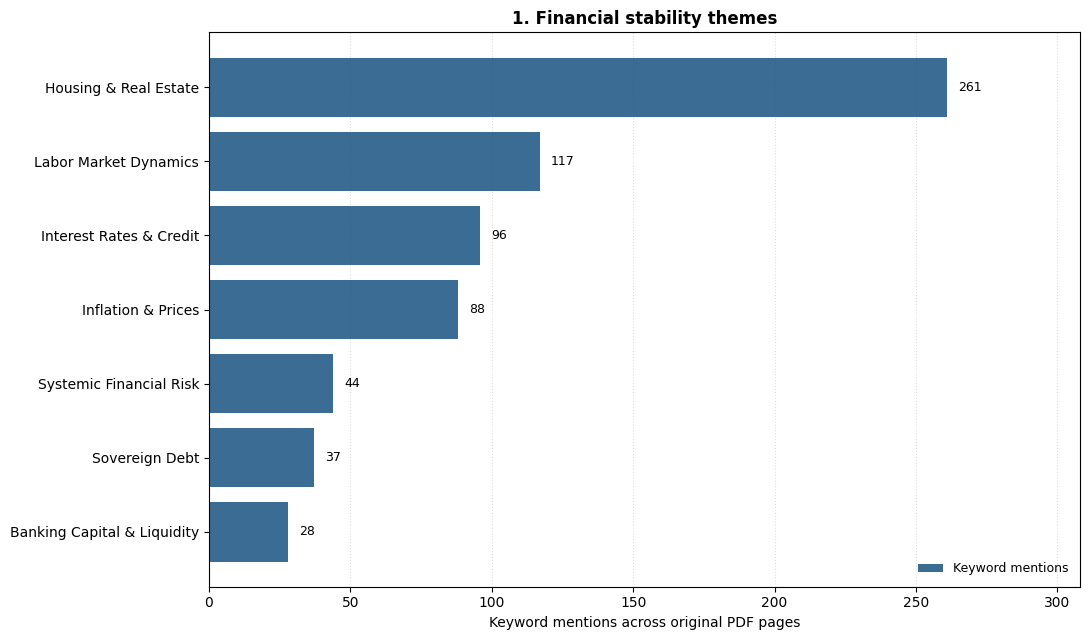

Saved: Figure_1_Thematic_Distribution.png


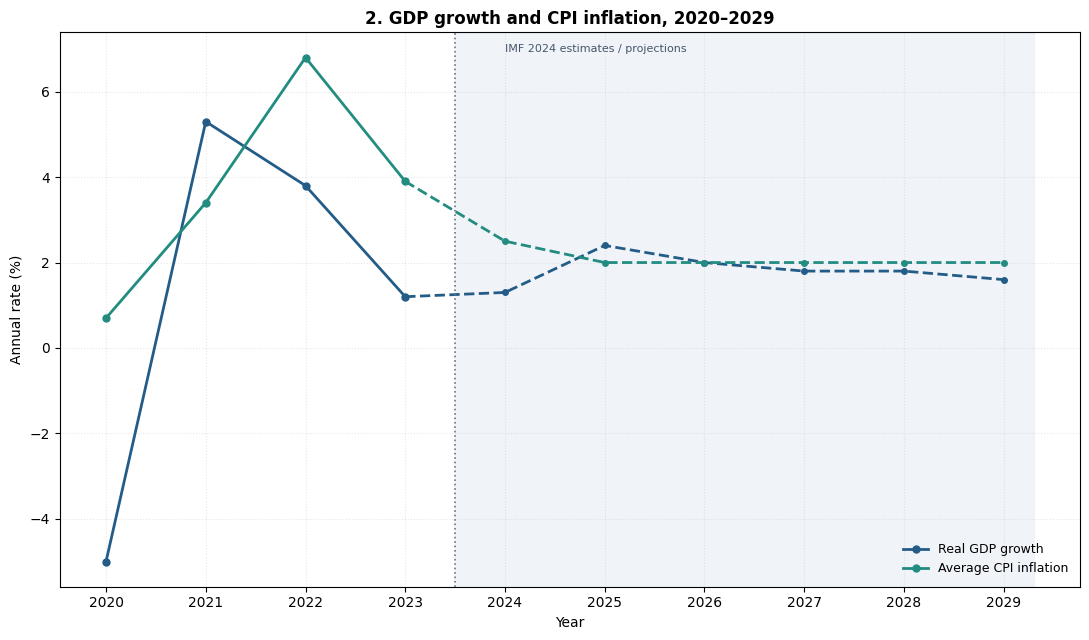

Saved: Figure_2_Inflation_GDP_Trends.png


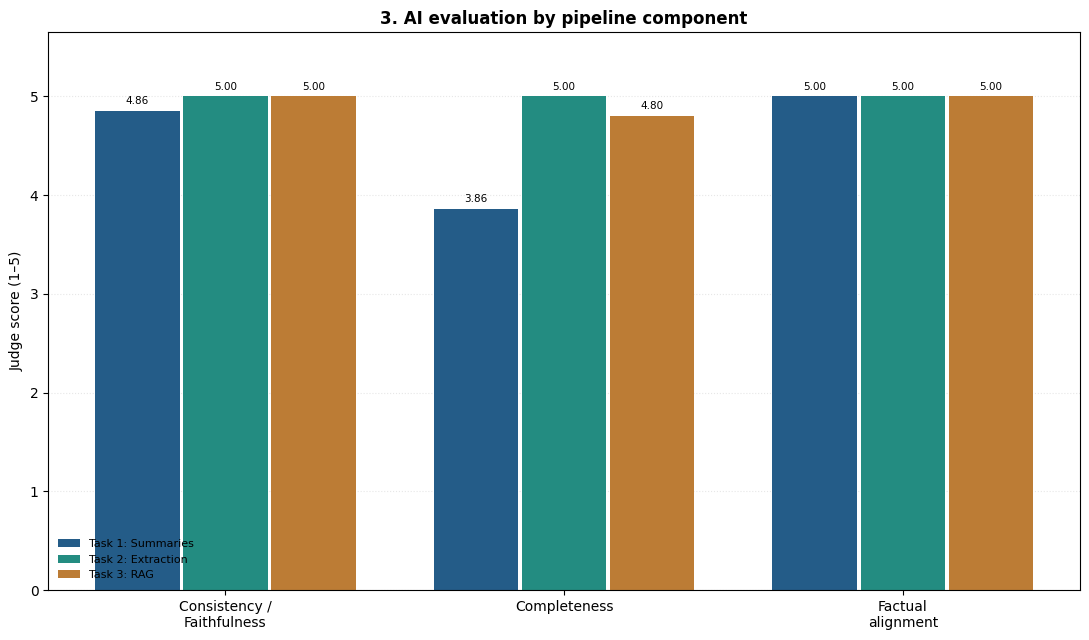

Saved: Figure_3_LLM_Judge_Scores.png


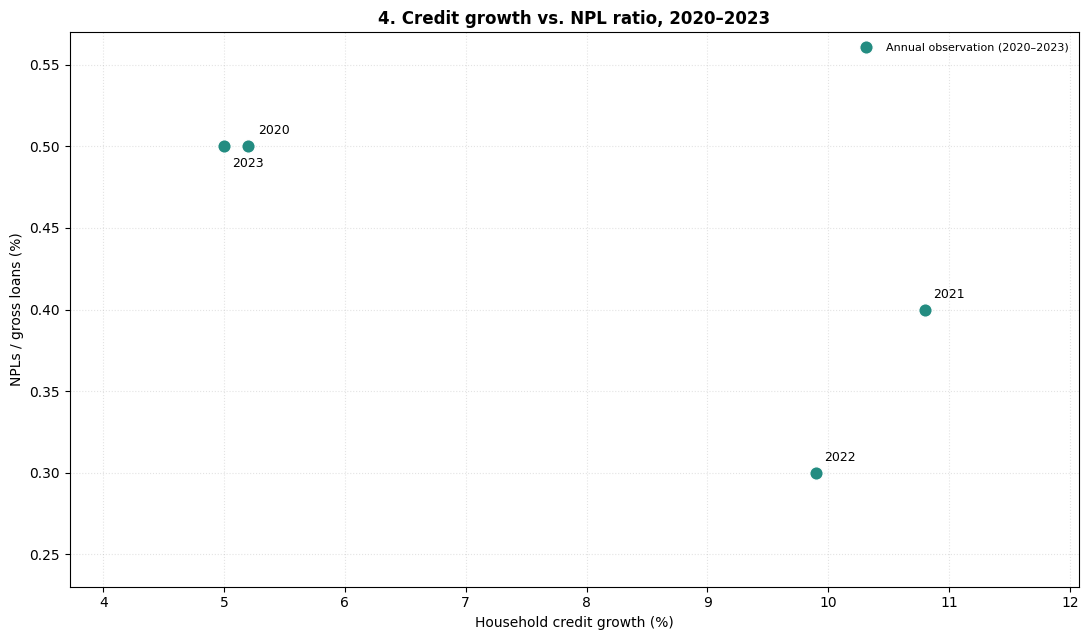

Saved: Figure_4_Credit_vs_NPL.png

Four individual graphs generated.


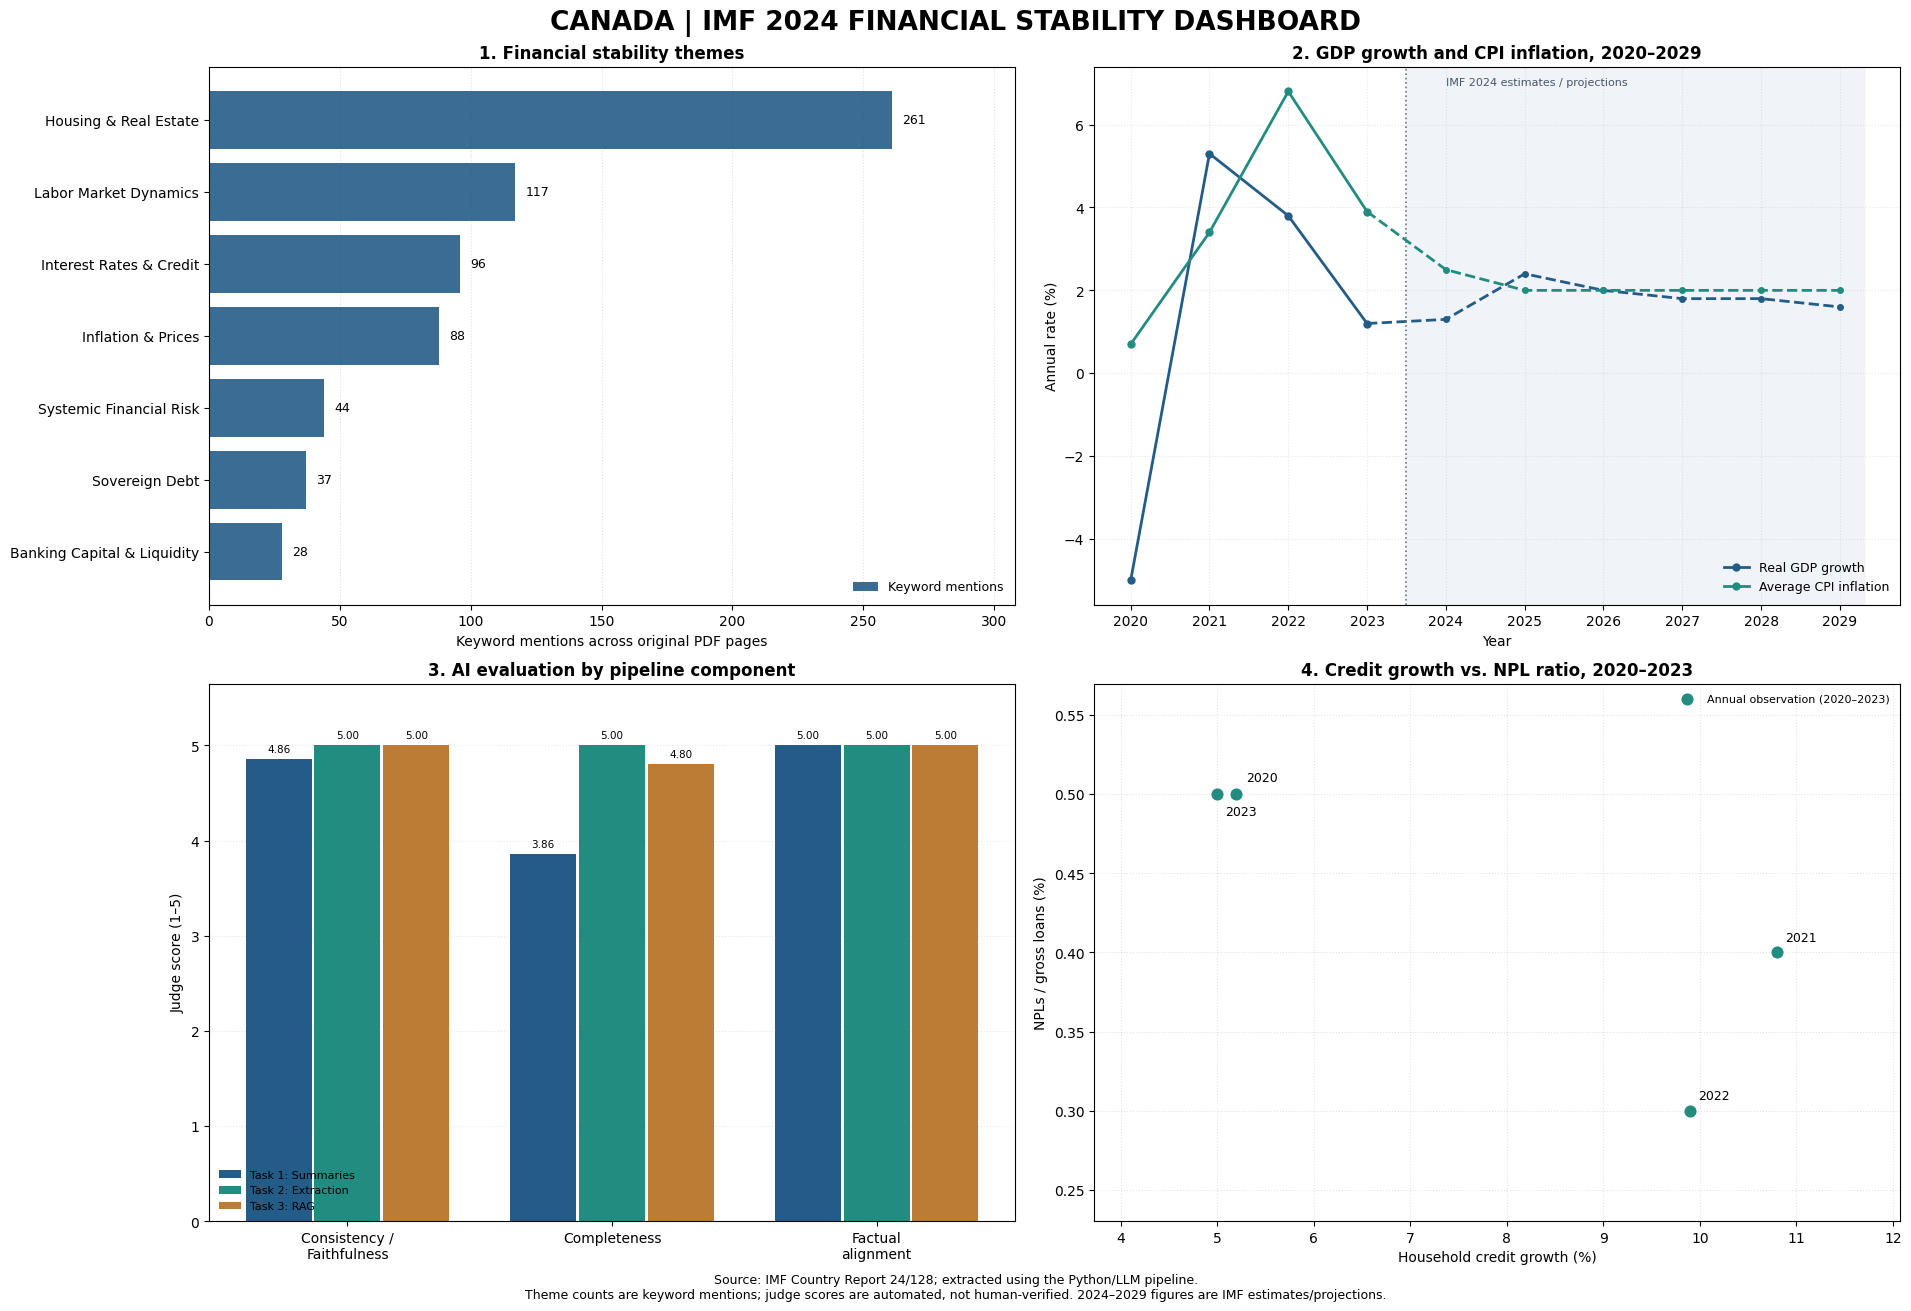


Combined executive dashboard generated!
Dashboard saved: /content/IMF_Task4_Outputs/figures/Executive_Dashboard_4_Plots.png

DASHBOARD ANALYSIS METADATA SAVED

FIGURE QUALITY VERIFICATION:


,figure,exists,dpi_x,dpi_y
0,Figure_1_Thematic_Distribution.png,True,300,300
1,Figure_2_Inflation_GDP_Trends.png,True,300,300
2,Figure_3_LLM_Judge_Scores.png,True,300,300
3,Figure_4_Credit_vs_NPL.png,True,300,300



TASK 4 COMPLETED SUCCESSFULLY!

Four high-resolution figures saved in:
/content/IMF_Task4_Outputs/figures

Data tables and evaluations saved in:
/content/IMF_Task4_Outputs

Downloadable ZIP created:
/content/IMF_Task4_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:


# TASK 4 — IMF CANADA 2024 FINANCIAL DASHBOARD


import json
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image as PILImage
from IPython.display import display


#  SETUP AND LOAD TASK 2 DATA


TASK2 = Path("/content/IMF_Task2_Outputs")
TASK3 = Path("/content/IMF_Task3_Outputs")
TASK4 = Path("/content/IMF_Task4_Outputs")
FIGURES = TASK4 / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)

required = {
    "Theme distribution":
        TASK2 / "thematic_distribution.csv",
    "Economic trends":
        TASK2 / "economic_trends_wide.csv",
    "Credit and NPL series":
        TASK2 / "credit_vs_npl.csv"
}

missing = [
    f"{label}: {path}"
    for label, path in required.items()
    if not path.exists()
]

if missing:
    raise FileNotFoundError(
        "Run Task 2 first. Missing files:\n"
        + "\n".join(missing)
    )

themes = pd.read_csv(
    required["Theme distribution"]
)

trends = pd.read_csv(
    required["Economic trends"]
).sort_values("year")

credit_npl = pd.read_csv(
    required["Credit and NPL series"]
).sort_values("year")

print("TASK 4 STARTED")
print("Theme categories:", len(themes))
print("Years in economic trends:", len(trends))
print("Credit/NPL observations:", len(credit_npl))


#  TIDY DATA TRANSFORMATION USING pd.melt()


series_names = {
    "real_gdp_growth_pct":
        "Real GDP growth",
    "cpi_annual_average_pct":
        "Average CPI inflation",
    "unemployment_annual_average_pct":
        "Unemployment",
    "household_credit_growth_pct":
        "Household credit growth",
    "general_government_gross_debt_pct_gdp":
        "Gross government debt (% GDP)"
}

trends_long = pd.melt(
    trends,
    id_vars=["year", "data_type"],
    value_vars=list(series_names),
    var_name="indicator",
    value_name="value"
)

trends_long["indicator_name"] = (
    trends_long["indicator"].map(series_names)
)

trends_long.to_csv(
    TASK4 / "economic_trends_long_tidy.csv",
    index=False
)

print("\nTIDY LONG-FORMAT DATA:")
display(trends_long.head(12))


#  LOAD ACTUAL LLM EVALUATION SCORES


score_rows = []

# Task 1: Section summarisation scores
summary_csv = Path(
    "/content/imf_evaluation_scores.csv"
)

summary_json = Path(
    "/content/imf_summary_evaluations.json"
)

if summary_csv.exists():

    summary_scores = pd.read_csv(summary_csv)
    summary_scores.columns = (
        summary_scores.columns.str.strip()
    )

    score_rows.append({
        "component": "Task 1: Summaries",
        "Consistency / Faithfulness":
            float(summary_scores["Consistency"].mean()),
        "Completeness":
            float(summary_scores["Completeness"].mean()),
        "Factual alignment":
            float(summary_scores["Factual Alignment"].mean())
    })

elif summary_json.exists():

    saved = json.loads(
        summary_json.read_text(encoding="utf-8")
    )

    valid = [
        value
        for value in saved.values()
        if isinstance(value, dict)
        and all(
            key in value
            for key in [
                "consistency",
                "completeness",
                "factual_alignment"
            ]
        )
    ]

    if valid:
        score_rows.append({
            "component": "Task 1: Summaries",
            "Consistency / Faithfulness":
                float(np.mean([
                    v["consistency"] for v in valid
                ])),
            "Completeness":
                float(np.mean([
                    v["completeness"] for v in valid
                ])),
            "Factual alignment":
                float(np.mean([
                    v["factual_alignment"] for v in valid
                ]))
        })

# Task 2: Financial indicator extraction scores
task2_scores_path = (
    TASK2 / "task2_evaluation_scores.csv"
)

if task2_scores_path.exists():

    e2 = pd.read_csv(task2_scores_path)

    score_rows.append({
        "component": "Task 2: Extraction",
        "Consistency / Faithfulness":
            float(e2["Consistency"].mean()),
        "Completeness":
            float(e2["Completeness"].mean()),
        "Factual alignment":
            float(e2["Factual Alignment"].mean())
    })

# Task 3: RAG evaluation scores
rag_csv = TASK3 / "rag_evaluation_scores.csv"
rag_json = TASK3 / "rag_evaluations.json"

if rag_csv.exists():

    e3 = pd.read_csv(rag_csv)

elif rag_json.exists():

    d3 = json.loads(
        rag_json.read_text(encoding="utf-8")
    )

    e3 = pd.DataFrame(
        list(d3.values())
    )

else:
    e3 = pd.DataFrame()

if not e3.empty:

    score_rows.append({
        "component": "Task 3: RAG",
        "Consistency / Faithfulness":
            float(e3["faithfulness"].mean()),
        "Completeness":
            float(e3["completeness"].mean()),
        "Factual alignment":
            float(e3["factual_alignment"].mean())
    })


# Restore previous evaluation scores if Colab restarted
if not score_rows:
    import pandas as pd
    import zipfile
    import io
    from pathlib import Path
    from google.colab import files

    print("Evaluation variables are missing.")
    print("Restoring previously generated Task 4 scores...")

    # Look for an existing Task 4 results ZIP
    zip_files = list(
        Path("/content").glob("IMF_Task4_Results*.zip")
    )

    if zip_files:
        zip_path = zip_files[-1]
    else:
        print("Upload IMF_Task4_Results.zip")
        uploaded = files.upload()

        zip_name = next(
            (
                name for name in uploaded
                if name.lower().endswith(".zip")
            ),
            None
        )

        if zip_name is None:
            raise FileNotFoundError(
                "Please upload your Task 4 Results ZIP."
            )

        zip_path = Path("/content") / zip_name

    # Load the original recorded evaluation scores
    with zipfile.ZipFile(zip_path, "r") as z:
        matches = [
            name for name in z.namelist()
            if Path(name).name == "evaluation_scores_wide.csv"
        ]

        if not matches:
            raise FileNotFoundError(
                "evaluation_scores_wide.csv "
                "was not found inside the ZIP."
            )

        df = pd.read_csv(
            io.BytesIO(z.read(matches[0]))
        )

    required_columns = [
        "component",
        "Consistency / Faithfulness",
        "Completeness",
        "Factual alignment"
    ]

    if not set(required_columns).issubset(df.columns):
        raise ValueError(
            "Evaluation CSV does not contain "
            "the expected score columns."
        )

    # Restore the score_rows variable
    score_rows = df[required_columns].to_dict(
        orient="records"
    )

    print("\nSUCCESS: Evaluation scores restored!")
    print(df[required_columns].to_string(index=False))


scores_wide = pd.DataFrame(score_rows)

scores_long = pd.melt(
    scores_wide,
    id_vars="component",
    value_vars=[
        "Consistency / Faithfulness",
        "Completeness",
        "Factual alignment"
    ],
    var_name="criterion",
    value_name="judge_score"
)

scores_wide.to_csv(
    TASK4 / "evaluation_scores_wide.csv",
    index=False
)

scores_long.to_csv(
    TASK4 / "evaluation_scores_long_tidy.csv",
    index=False
)

print("\nLLM EVALUATION COMPARISON:")
display(scores_wide.round(2))


#  PROFESSIONAL CHART STYLING


plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})

BLUE = "#245C88"
TEAL = "#238C81"
GOLD = "#BC7C35"


# FIGURE 1 — THEMATIC DISTRIBUTION


def draw_themes(ax):

    data = themes.sort_values(
        "occurrences",
        ascending=True
    )

    ax.barh(
        data["theme"],
        data["occurrences"],
        color=BLUE,
        alpha=0.9,
        label="Keyword mentions"
    )

    ax.set_xlabel(
        "Keyword mentions across original PDF pages"
    )

    ax.set_title(
        "1. Financial stability themes"
    )

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.4
    )

    ax.set_axisbelow(True)

    ax.legend(
        loc="lower right",
        frameon=False
    )

    max_value = max(
        1,
        float(data["occurrences"].max())
    )

    ax.set_xlim(
        0,
        max_value * 1.18
    )

    for i, count in enumerate(
        data["occurrences"]
    ):

        ax.text(
            count + max_value * 0.015,
            i,
            str(int(count)),
            va="center",
            fontsize=9
        )


# FIGURE 2 — GDP GROWTH AND INFLATION TRENDS


def draw_trends(ax):

    series = [
        (
            "real_gdp_growth_pct",
            "Real GDP growth",
            BLUE
        ),
        (
            "cpi_annual_average_pct",
            "Average CPI inflation",
            TEAL
        )
    ]

    historical = trends[
        trends["year"] <= 2023
    ]

    # Include 2023 to connect historical
    # and projected trajectories.
    future = trends[
        trends["year"] >= 2023
    ]

    # Highlight forecast period.
    ax.axvspan(
        2023.5,
        2029.3,
        color="#EBF1F7",
        alpha=0.75
    )

    for field, label, color in series:

        ax.plot(
            historical["year"],
            historical[field],
            "-o",
            color=color,
            linewidth=2,
            markersize=5,
            label=label
        )

        ax.plot(
            future["year"],
            future[field],
            "--o",
            color=color,
            linewidth=2,
            markersize=4
        )

    ax.axvline(
        2023.5,
        color="#687681",
        linestyle=":",
        linewidth=1.2
    )

    ax.text(
        2024,
        ax.get_ylim()[1] - 0.45,
        "IMF 2024 estimates / projections",
        fontsize=8,
        color="#475569"
    )

    ax.set_xticks(
        trends["year"].tolist()
    )

    ax.set_xlabel("Year")
    ax.set_ylabel("Annual rate (%)")

    ax.set_title(
        "2. GDP growth and CPI inflation, 2020–2029"
    )

    ax.grid(
        alpha=0.3,
        linestyle=":"
    )

    ax.legend(
        loc="lower right",
        frameon=False
    )

# FIGURE 3 — LLM-AS-A-JUDGE COMPARISON

def draw_judge(ax):

    metrics = [
        "Consistency / Faithfulness",
        "Completeness",
        "Factual alignment"
    ]

    palette = [
        BLUE,
        TEAL,
        GOLD
    ]

    x = np.arange(len(metrics))

    number_of_components = len(
        scores_wide
    )

    bar_width = (
        0.78 / number_of_components
    )

    for i, (_, row) in enumerate(
        scores_wide.iterrows()
    ):

        offsets = (
            x +
            (i - (number_of_components - 1) / 2)
            * bar_width
        )

        heights = [
            row[metric]
            for metric in metrics
        ]

        bars = ax.bar(
            offsets,
            heights,
            width=bar_width * 0.96,
            label=row["component"],
            color=palette[i % len(palette)]
        )

        for rect, value in zip(
            bars,
            heights
        ):

            ax.text(
                rect.get_x()
                + rect.get_width() / 2,
                value + 0.07,
                f"{value:.2f}",
                fontsize=7.5,
                ha="center"
            )

    ax.set_xticks(x)

    ax.set_xticklabels([
        "Consistency /\nFaithfulness",
        "Completeness",
        "Factual\nalignment"
    ])

    ax.set_ylim(0, 5.65)

    ax.set_ylabel(
        "Judge score (1–5)"
    )

    ax.set_title(
        "3. AI evaluation by pipeline component"
    )

    ax.grid(
        axis="y",
        alpha=0.3,
        linestyle=":"
    )

    ax.set_axisbelow(True)

    ax.legend(
        loc="lower left",
        frameon=False,
        fontsize=8
    )

# FIGURE 4 — CREDIT GROWTH VS NPL RATIO


def draw_credit_npl(ax):

    x = pd.to_numeric(
        credit_npl["household_credit_growth_pct"]
    )

    y = pd.to_numeric(
        credit_npl["npl_to_gross_loans_pct"]
    )

    ax.scatter(
        x,
        y,
        s=95,
        color=TEAL,
        edgecolor="white",
        linewidth=1,
        label="Annual observation (2020–2023)",
        zorder=3
    )

    for _, row in credit_npl.iterrows():

        year = int(row["year"])

        offset = {
            2020: (7, 9),
            2021: (6, 8),
            2022: (6, 8),
            2023: (6, -15)
        }.get(year, (6, 8))

        ax.annotate(
            str(year),
            (
                row["household_credit_growth_pct"],
                row["npl_to_gross_loans_pct"]
            ),
            xytext=offset,
            textcoords="offset points",
            fontsize=9
        )

    ax.margins(
        x=0.22,
        y=0.35
    )

    ax.set_xlabel(
        "Household credit growth (%)"
    )

    ax.set_ylabel(
        "NPLs / gross loans (%)"
    )

    ax.set_title(
        "4. Credit growth vs. NPL ratio, 2020–2023"
    )

    ax.grid(
        alpha=0.35,
        linestyle=":"
    )

    ax.set_axisbelow(True)

    ax.legend(
        loc="upper right",
        frameon=False,
        fontsize=8
    )


# GENERATE FOUR SEPARATE 300 DPI FIGURES


plotters = [
    (
        "Figure_1_Thematic_Distribution.png",
        draw_themes
    ),
    (
        "Figure_2_Inflation_GDP_Trends.png",
        draw_trends
    ),
    (
        "Figure_3_LLM_Judge_Scores.png",
        draw_judge
    ),
    (
        "Figure_4_Credit_vs_NPL.png",
        draw_credit_npl
    )
]

for filename, plot_function in plotters:

    fig, ax = plt.subplots(
        figsize=(11, 6.5)
    )

    plot_function(ax)

    fig.tight_layout()

    fig.savefig(
        FIGURES / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", filename)

print("\nFour individual graphs generated.")

# CREATE COMBINED EXECUTIVE DASHBOARD


fig, axes = plt.subplots(
    2,
    2,
    figsize=(19, 13),
    constrained_layout=True
)

for ax, (_, plot_function) in zip(
    axes.flat,
    plotters
):

    plot_function(ax)

fig.suptitle(
    "CANADA | IMF 2024 FINANCIAL STABILITY DASHBOARD",
    fontsize=19,
    fontweight="bold"
)

fig.supxlabel(
    "Source: IMF Country Report 24/128; "
    "extracted using the Python/LLM pipeline.\n"
    "Theme counts are keyword mentions; "
    "judge scores are automated, not human-verified. "
    "2024–2029 figures are IMF estimates/projections.",
    fontsize=9
)

dashboard_path = (
    FIGURES / "Executive_Dashboard_4_Plots.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nCombined executive dashboard generated!")
print("Dashboard saved:", dashboard_path)


#  SAVE ANALYTICAL FINDINGS


dashboard_summary = {

    "source":
        "IMF Country Report 24/128, Canada 2024",

    "theme_mentions_total":
        int(themes["occurrences"].sum()),

    "most_mentioned_theme":
        str(
            themes.sort_values(
                "occurrences",
                ascending=False
            ).iloc[0]["theme"]
        ),

    "most_mentioned_theme_count":
        int(themes["occurrences"].max()),

    "gdp_growth_2023_pct":
        float(
            trends.loc[
                trends["year"] == 2023,
                "real_gdp_growth_pct"
            ].iloc[0]
        ),

    "gdp_growth_2024_imf_estimate_pct":
        float(
            trends.loc[
                trends["year"] == 2024,
                "real_gdp_growth_pct"
            ].iloc[0]
        ),

    "cpi_2024_imf_average_estimate_pct":
        float(
            trends.loc[
                trends["year"] == 2024,
                "cpi_annual_average_pct"
            ].iloc[0]
        ),

    "historical_credit_npl_observations":
        int(len(credit_npl)),

    "evaluation_components_in_plot":
        scores_wide["component"].tolist(),

    "limitations": [

        "Keyword frequencies measure mentions, "
        "not economic risk probabilities.",

        "LLM judge scores do not independently "
        "establish factual accuracy.",

        "RAG faithfulness is used as the closest "
        "equivalent to consistency.",

        "2024–2029 economic values are IMF "
        "estimates or projections from 2024.",

        "The credit/NPL scatter contains only "
        "four annual observations.",

        "No verified policy-rate trend was "
        "available from the extracted dataset."
    ]
}

with open(
    TASK4 / "dashboard_analysis_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        dashboard_summary,
        f,
        indent=2
    )

print("\nDASHBOARD ANALYSIS METADATA SAVED")


#  AUTOMATIC FIGURE QUALITY VERIFICATION


quality_results = []

for filename, _ in plotters:

    path = FIGURES / filename

    with PILImage.open(path) as image:

        dpi = image.info.get(
            "dpi",
            (0, 0)
        )

        quality_results.append({
            "figure": filename,
            "exists": path.exists(),
            "dpi_x": round(dpi[0]),
            "dpi_y": round(dpi[1])
        })

quality_df = pd.DataFrame(
    quality_results
)

quality_df.to_csv(
    TASK4 / "figure_quality_check.csv",
    index=False
)

print("\nFIGURE QUALITY VERIFICATION:")
display(quality_df)

assert (
    len(quality_df) >= 4
    and quality_df["exists"].all()
), "Some dashboard figures are missing."

assert (
    quality_df[
        ["dpi_x", "dpi_y"]
    ] >= 299
).all().all(), (
    "One or more plots have insufficient resolution."
)

#  CREATE DOWNLOADABLE RESULTS PACKAGE

archive = shutil.make_archive(
    "/content/IMF_Task4_Results",
    "zip",
    root_dir=str(TASK4)
)

print("\n" + "=" * 65)
print("TASK 4 COMPLETED SUCCESSFULLY!")
print("=" * 65)

print("\nFour high-resolution figures saved in:")
print(FIGURES)

print("\nData tables and evaluations saved in:")
print(TASK4)

print("\nDownloadable ZIP created:")
print(archive)

# Automatically download the Task 4 results ZIP.
from google.colab import files
files.download(archive)
